# TerraMatch AI — Etapa 1: DEM real de Jezero (Marte)

**Objetivo:** baixar um modelo digital de elevação (DEM) oficial do USGS, inspecionar os metadados, conferir valores válidos e visualizar a topografia. **Não estamos calculando correspondências terrestres nesta etapa.**

Fonte: [USGS — Mars 2020 Terrain Relative Navigation CTX DTM Mosaic](https://astrogeology.usgs.gov/search/map/Mars/Mars2020/JEZ_ctx_B_soc_008_DTM_MOLAtopography_DeltaGeoid_20m_Eqc_latTs0_lon0) (CTX, 20 m/pixel). O produto cobre uma parte de Jezero, não a cratera inteira.

In [2]:
%pip -q install rasterio matplotlib numpy

In [3]:
from pathlib import Path
from urllib.request import Request, urlopen
import shutil

pasta = Path('/content/terramatch/data/raw/mars')
pasta.mkdir(parents=True, exist_ok=True)
url = 'https://planetarymaps.usgs.gov/mosaic/mars2020_trn/CTX/JEZ_ctx_B_soc_008_DTM_MOLAtopography_DeltaGeoid_20m_Eqc_latTs0_lon0.tif'
arquivo = pasta / 'jezero_ctx_dem_20m.tif'

if not arquivo.exists() or arquivo.stat().st_size == 0:
    req = Request(url, headers={'User-Agent': 'TerraMatchAI-Research/1.0'})
    with urlopen(req, timeout=90) as resposta, open(arquivo, 'wb') as destino:
        shutil.copyfileobj(resposta, destino)
print('Arquivo:', arquivo)
print('Tamanho: %.2f MB' % (arquivo.stat().st_size / 1024**2))

Arquivo: /content/terramatch/data/raw/mars/jezero_ctx_dem_20m.tif
Tamanho: 9.21 MB


In [4]:
import numpy as np
import rasterio

with rasterio.open(arquivo) as dem:
    print('Dimensões:', dem.width, 'x', dem.height)
    print('Resolução (unidades do CRS):', dem.res)
    print('CRS:', dem.crs)
    print('NoData:', dem.nodata)
    print('Limites:', dem.bounds)
    print('Bandas:', dem.count)
    amostra = dem.read(1, masked=True, out_shape=(min(dem.height, 900), min(dem.width, 900)))

valores = amostra.compressed().astype('float64')
valores = valores[np.isfinite(valores)]
if len(valores)==0:
    raise ValueError('Nenhuma elevação válida foi encontrada. Verifique o arquivo.')
print('Pixels válidos na amostra:', len(valores))
print('Elevação mínima (amostra): %.2f m' % valores.min())
print('Elevação máxima (amostra): %.2f m' % valores.max())
print('Elevação média (amostra): %.2f m' % valores.mean())

Dimensões: 1596 x 1512
Resolução (unidades do CRS): (20.0, 20.0)
CRS: ESRI:103885
NoData: -3.4028226550889045e+38
Limites: BoundingBox(left=4573663.250853, bottom=1079453.140188, right=4605583.250853, top=1109693.140188)
Bandas: 1
Pixels válidos na amostra: 810000
Elevação mínima (amostra): -2710.69 m
Elevação máxima (amostra): -1515.68 m
Elevação média (amostra): -2356.88 m


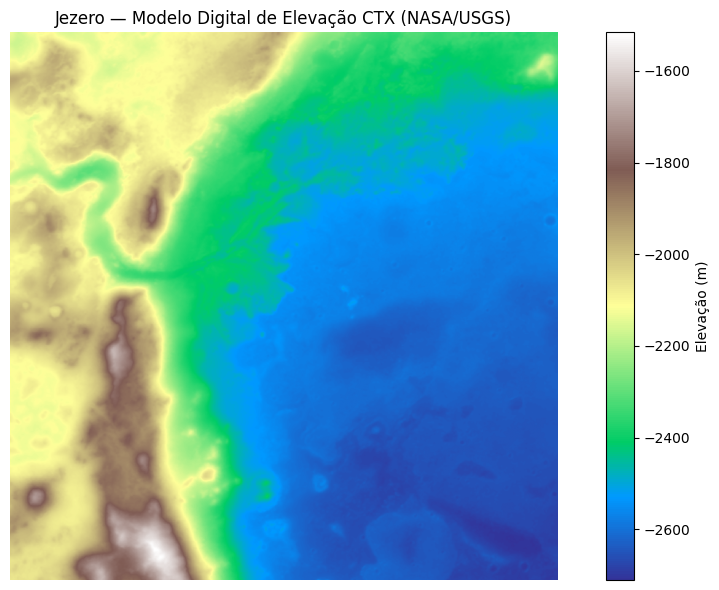

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.imshow(amostra, cmap='terrain', origin='upper')
plt.title('Jezero — Modelo Digital de Elevação CTX (NASA/USGS)')
plt.axis('off')
plt.colorbar(label='Elevação (m)')
plt.tight_layout()
plt.show()

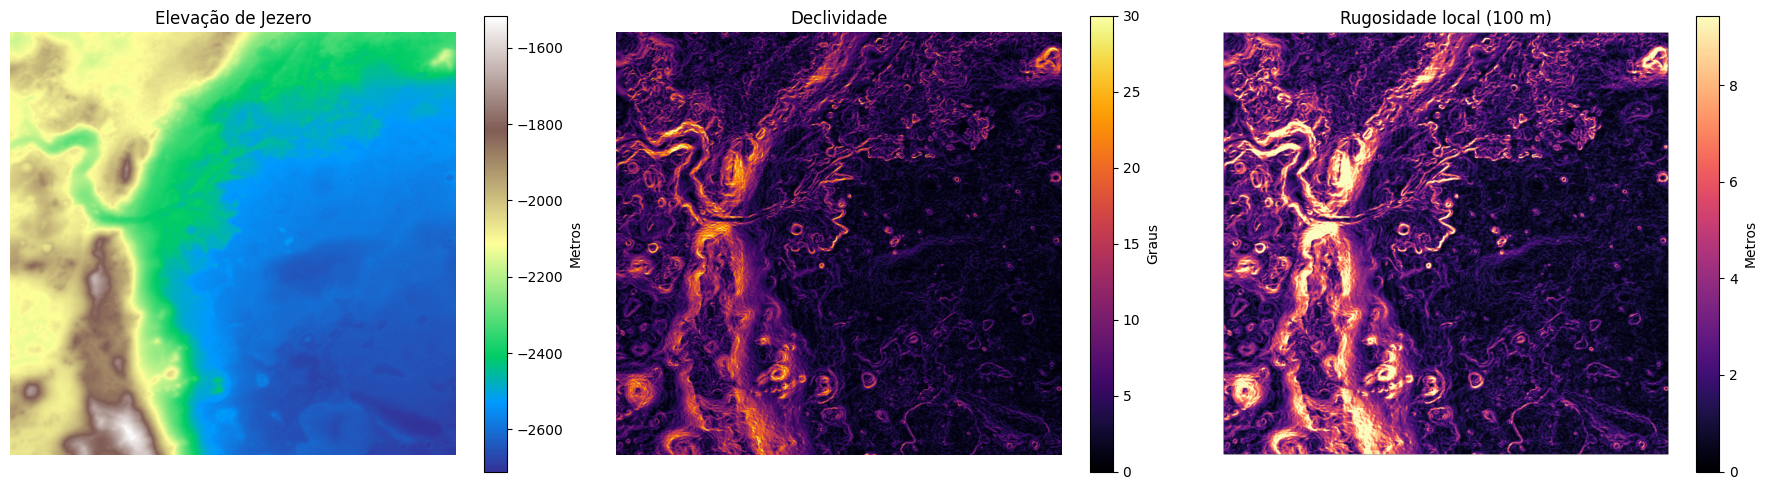

=== JEZERO: ATRIBUTOS TOPOGRÁFICOS ===
Declividade média: 5.00 graus
Declividade mediana: 3.37 graus
Declividade P90: 11.59 graus
Rugosidade média: 2.48 m
Rugosidade P90: 5.71 m
Amplitude topográfica: 1195.16 m


In [6]:

import numpy as np                                                  # Biblioteca para operações numéricas e estatísticas.
import rasterio                                                     # Biblioteca para leitura de dados geoespaciais.
import matplotlib.pyplot as plt                                     # Biblioteca para criação dos gráficos.
from scipy.ndimage import uniform_filter                            # Filtro utilizado para calcular estatísticas locais.


caminho = "/content/terramatch/data/raw/mars/jezero_ctx_dem_20m.tif"  # Caminho do modelo digital de elevação de Jezero.


with rasterio.open(caminho) as src:                                 # Abre o arquivo geoespacial.
    dem = src.read(1, masked=True).astype(np.float64)               # Lê a primeira banda e identifica pixels sem dados.
    resolucao_x = abs(src.transform.a)                              # Obtém o tamanho horizontal do pixel em metros.
    resolucao_y = abs(src.transform.e)                              # Obtém o tamanho vertical do pixel em metros.


valido = ~np.ma.getmaskarray(dem)                                   # Identifica os pixels que possuem elevações válidas.
z = dem.filled(np.nan)                                               # Substitui os valores ausentes por NaN.


dz_dy, dz_dx = np.gradient(z, resolucao_y, resolucao_x)             # Calcula as derivadas espaciais da elevação.

declividade = np.degrees(                                           # Converte a inclinação do terreno para graus.
    np.arctan(np.sqrt(dz_dx**2 + dz_dy**2))                         # Calcula o ângulo a partir do módulo do gradiente.
)

declividade[~np.isfinite(declividade)] = np.nan                     # Remove resultados afetados por pixels inválidos.
declividade[~valido] = np.nan                                       # Mantém os pixels sem dados fora da análise.


janela = 5                                                          # Define uma janela local de 5 x 5 pixels.
pesos = valido.astype(np.float64)                                   # Converte a máscara de validade em valores 0 e 1.
alturas = np.where(valido, z, 0.0)                                  # Substitui pixels inválidos por zero nas operações.


contagem = uniform_filter(                                          # Calcula a proporção de pixels válidos na janela.
    pesos, size=janela, mode="constant", cval=0
)

media = uniform_filter(                                             # Calcula a soma local normalizada das elevações.
    alturas, size=janela, mode="constant", cval=0
) / np.maximum(contagem, 1e-12)                                     # Obtém a média sem dividir por zero.


media_quadrados = uniform_filter(                                   # Calcula a média local dos quadrados das elevações.
    alturas**2, size=janela, mode="constant", cval=0
) / np.maximum(contagem, 1e-12)                                     # Considera somente os pixels válidos.


variancia = np.maximum(                                             # Calcula a variância local das elevações.
    media_quadrados - media**2, 0                                   # Impede pequenas variâncias negativas numéricas.
)

rugosidade = np.sqrt(variancia)                                     # Calcula o desvio-padrão local em metros.

rugosidade[contagem < 0.999999] = np.nan                            # Descarta janelas que não possuem todos os pixels.
rugosidade[~valido] = np.nan                                        # Exclui pixels sem elevação válida.


fig, axs = plt.subplots(1, 3, figsize=(18, 5))                      # Cria uma figura com três gráficos lado a lado.

im0 = axs[0].imshow(z, cmap="terrain")                              # Exibe o mapa de elevação.
axs[0].set_title("Elevação de Jezero")                              # Define o título do primeiro gráfico.
plt.colorbar(im0, ax=axs[0], label="Metros")                        # Adiciona a escala de elevação.


im1 = axs[1].imshow(                                                # Exibe o mapa de declividade.
    declividade, cmap="inferno", vmin=0, vmax=30                    # Utiliza uma escala visual de 0 a 30 graus.
)
axs[1].set_title("Declividade")                                     # Define o título do segundo gráfico.
plt.colorbar(im1, ax=axs[1], label="Graus")                         # Adiciona a escala angular.


im2 = axs[2].imshow(                                                # Exibe o mapa de rugosidade.
    rugosidade, cmap="magma",                                       # Utiliza uma escala de cores para variação local.
    vmin=0,                                                         # Define o valor mínimo da escala como zero.
    vmax=np.nanpercentile(rugosidade, 98)                           # Limita a escala ao percentil 98.
)
axs[2].set_title("Rugosidade local (100 m)")                        # Define o título do terceiro gráfico.
plt.colorbar(im2, ax=axs[2], label="Metros")                        # Adiciona a escala de rugosidade.


for ax in axs:                                                      # Percorre os três gráficos.
    ax.axis("off")                                                  # Oculta os eixos para melhorar a visualização.

plt.tight_layout()                                                  # Ajusta automaticamente os espaçamentos.
plt.show()                                                          # Exibe os três mapas.


print("=== JEZERO: ATRIBUTOS TOPOGRÁFICOS ===")                     # Imprime o cabeçalho dos resultados.
print(f"Declividade média: {np.nanmean(declividade):.2f} graus")     # Calcula a média das inclinações.
print(f"Declividade mediana: {np.nanmedian(declividade):.2f} graus") # Calcula a mediana das inclinações.
print(f"Declividade P90: {np.nanpercentile(declividade, 90):.2f} graus") # Calcula o percentil 90 da declividade.
print(f"Rugosidade média: {np.nanmean(rugosidade):.2f} m")          # Calcula a rugosidade média em metros.
print(f"Rugosidade P90: {np.nanpercentile(rugosidade, 90):.2f} m")   # Calcula o percentil 90 da rugosidade.
print(f"Amplitude topográfica: {np.nanmax(z)-np.nanmin(z):.2f} m")   # Calcula a diferença entre a maior e a menor elevação.


In [ ]:

# =============================================================================
# ETAPA 3 — SELEÇÃO E CARACTERIZAÇÃO TOPOGRÁFICA DOS SETORES DE JEZERO
# Objetivo: selecionar três setores de 5 × 5 km e calcular seus atributos.
# Entrada: DEM, declividade e rugosidade calculados nas etapas anteriores.
# Saídas: mapa dos setores, tabela de atributos, arquivos CSV e JSON.
# Fonte: Modelo Digital de Elevação CTX — NASA/USGS.
# =============================================================================

import os                                                               # Permite criar diretórios para armazenar os resultados.
import json                                                             # Permite salvar os atributos no formato JSON.
import numpy as np                                                      # Realiza operações numéricas com as matrizes.
import pandas as pd                                                     # Organiza os resultados em tabelas.
import matplotlib.pyplot as plt                                         # Cria os mapas e as visualizações.
from matplotlib.patches import Rectangle                                # Permite desenhar os limites dos setores.


pasta_saida = "/content/terramatch/data/processed"                      # Define o diretório para os dados processados.
os.makedirs(pasta_saida, exist_ok=True)                                 # Cria o diretório caso ainda não exista.


tamanho_km = 5                                                          # Define o lado de cada setor em quilômetros.
pixels_setor = round(tamanho_km * 1000 / resolucao_x)                    # Converte o tamanho físico em quantidade de pixels.

assert np.isclose(resolucao_x, resolucao_y)                              # Confirma que os pixels possuem dimensões iguais.
assert np.isclose(pixels_setor * resolucao_x, tamanho_km * 1000)         # Confirma que cada recorte possui aproximadamente 5 km.


setores = {                                                             # Define os centros dos três setores na matriz.
    "Jezero_01": (380, 320),                                             # Centro do setor localizado na porção superior esquerda.
    "Jezero_02": (720, 760),                                             # Centro do setor localizado na região central.
    "Jezero_03": (1100, 1200)                                            # Centro do setor localizado na porção inferior direita.
}                                                                       # Finaliza a definição dos setores.


resultados = []                                                          # Cria a lista que armazenará as estatísticas.
recortes = {}                                                            # Cria o dicionário que armazenará os recortes.

fig, ax = plt.subplots(figsize=(10, 9))                                 # Cria a figura para mostrar os setores.
imagem = ax.imshow(z, cmap="terrain")                                   # Exibe o modelo digital de elevação.

cores = ["#ffcc66", "#ff7777", "#66eeff"]                                 # Define uma cor diferente para cada setor.


for i, (nome, (linha, coluna)) in enumerate(setores.items()):           # Percorre os setores previamente definidos.
    metade = pixels_setor // 2                                          # Calcula metade da largura de cada recorte.
    l0 = linha - metade                                                 # Define a primeira linha do recorte.
    c0 = coluna - metade                                                # Define a primeira coluna do recorte.
    l1 = l0 + pixels_setor                                              # Define a última linha exclusiva do recorte.
    c1 = c0 + pixels_setor                                              # Define a última coluna exclusiva do recorte.

    assert 0 <= l0 < l1 <= z.shape[0]                                    # Confirma que as linhas estão dentro do DEM.
    assert 0 <= c0 < c1 <= z.shape[1]                                    # Confirma que as colunas estão dentro do DEM.

    elev = z[l0:l1, c0:c1]                                               # Extrai as elevações correspondentes ao setor.
    slope = declividade[l0:l1, c0:c1]                                    # Extrai as declividades correspondentes ao setor.
    rough = rugosidade[l0:l1, c0:c1]                                     # Extrai as rugosidades correspondentes ao setor.

    cobertura = np.isfinite(elev).mean() * 100                           # Calcula o percentual de elevações válidas.
    assert cobertura >= 95                                              # Exige pelo menos 95% de cobertura de elevação.

    recortes[nome] = {                                                   # Armazena as matrizes e os limites do setor.
        "elevacao": elev,                                                # Guarda a matriz de elevação.
        "declividade": slope,                                            # Guarda a matriz de declividade.
        "rugosidade": rough,                                             # Guarda a matriz de rugosidade.
        "limites_pixels": [l0, l1, c0, c1]                               # Guarda os limites em índices de matriz.
    }                                                                    # Finaliza o registro do recorte.

    atributos = {                                                        # Cria o conjunto de características do setor.
        "regiao": nome,                                                  # Identifica o setor de Jezero.
        "planeta": "Marte",                                               # Identifica o corpo planetário de origem.
        "area_km2": tamanho_km**2,                                       # Registra a área de 25 quilômetros quadrados.
        "cobertura_valida_pct": round(float(cobertura), 2),              # Registra o percentual de elevações válidas.
        "declividade_media_graus": round(float(np.nanmean(slope)), 3),   # Calcula a declividade média.
        "declividade_mediana_graus": round(float(np.nanmedian(slope)), 3), # Calcula a mediana da declividade.
        "declividade_p90_graus": round(float(np.nanpercentile(slope, 90)), 3), # Calcula o percentil 90 da declividade.
        "rugosidade_media_m": round(float(np.nanmean(rough)), 3),        # Calcula a rugosidade média.
        "rugosidade_p90_m": round(float(np.nanpercentile(rough, 90)), 3), # Calcula o percentil 90 da rugosidade.
        "amplitude_topografica_m": round(float(np.nanmax(elev) - np.nanmin(elev)), 3) # Calcula a amplitude topográfica.
    }                                                                    # Finaliza o conjunto de características.

    resultados.append(atributos)                                        # Adiciona os atributos à lista de resultados.

    retangulo = Rectangle(                                              # Cria um retângulo correspondente ao setor.
        (c0, l0), pixels_setor, pixels_setor,                            # Informa posição e dimensões do recorte.
        linewidth=2.5, edgecolor=cores[i], facecolor="none"             # Define borda colorida e interior transparente.
    )                                                                    # Finaliza a criação do retângulo.

    ax.add_patch(retangulo)                                              # Desenha o limite do setor sobre o mapa.
    ax.text(c0, l0 - 12, nome, color=cores[i], fontsize=11,             # Identifica o setor acima do retângulo.
            fontweight="bold")                                          # Destaca visualmente o nome do setor.


ax.set_title("Jezero — Setores de análise topográfica (5 × 5 km)")       # Define o título do mapa.
ax.axis("off")                                                           # Oculta os eixos para destacar o terreno.
plt.colorbar(imagem, ax=ax, label="Elevação (m)", shrink=0.8)           # Adiciona a escala de elevação.
plt.tight_layout()                                                       # Ajusta os espaços da figura.
plt.savefig(f"{pasta_saida}/jezero_setores.png", dpi=200)               # Salva o mapa dos setores.
plt.show()                                                               # Exibe o mapa no notebook.


df = pd.DataFrame(resultados)                                           # Converte as características em uma tabela.
df.to_csv(f"{pasta_saida}/jezero_features.csv", index=False)            # Salva os atributos no formato CSV.

with open(f"{pasta_saida}/jezero_features.json", "w", encoding="utf-8") as arquivo: # Abre o arquivo JSON para escrita.
    json.dump(resultados, arquivo, indent=4, ensure_ascii=False)        # Salva as características de forma estruturada.

display(df.round(2))                                                     # Exibe a tabela de atributos calculados.
print(f"Arquivos salvos em: {pasta_saida}")                              # Mostra onde encontrar os arquivos.


In [ ]:

# =============================================================================
# ETAPA 4.1 — PREPARAÇÃO PARA AQUISIÇÃO DOS DADOS TERRESTRES
# Objetivo: preparar o ambiente para baixar e processar DEMs da Terra.
# Fonte: Mapzen Terrain Tiles — Amazon Web Services (AWS).
# Saída: bibliotecas disponíveis para a próxima célula.
# =============================================================================

%pip -q install mercantile                                           # Instala a biblioteca para localizar tiles geográficos.

import os                                                            # Permite organizar e criar diretórios.
import numpy as np                                                   # Realiza operações com matrizes numéricas.
import rasterio                                                      # Permite ler e salvar dados geoespaciais.
import requests                                                      # Permite baixar arquivos pela internet.
import mercantile                                                    # Calcula os índices dos tiles geográficos.
import matplotlib.pyplot as plt                                      # Permite visualizar os mapas de elevação.

from io import BytesIO                                               # Armazena arquivos baixados diretamente na memória.
from pyproj import Transformer                                       # Converte coordenadas entre sistemas geográficos.
from rasterio.io import MemoryFile                                   # Permite abrir arquivos GeoTIFF sem salvá-los previamente.
from rasterio.merge import merge                                     # Une tiles adjacentes em um único raster.
from rasterio.warp import reproject, Resampling                      # Reprojeta e reamostra os dados topográficos.
from rasterio.transform import from_origin                           # Cria a transformação espacial do raster.

print("Ambiente preparado para a Etapa 4.")                          # Confirma a execução da célula.


In [ ]:

# =============================================================================
# ETAPA 4.2 — AQUISIÇÃO E PROCESSAMENTO DO DEM DO ATACAMA
# Objetivo: obter um recorte terrestre de 5 x 5 km com dados reais.
# Região: Valle de la Luna — Deserto do Atacama, Chile.
# Fonte: Mapzen Terrain Tiles — AWS Public Dataset.
# Saídas: arquivo GeoTIFF, mapa de elevação e estatísticas preliminares.
# =============================================================================

latitude = -22.9112                                                 # Define a latitude central da região terrestre.
longitude = -68.3230                                                # Define a longitude central da região terrestre.
nome_regiao = "atacama_valle_luna"                                   # Identifica a região nos arquivos de saída.
tamanho_m = 5000                                                     # Define o lado do recorte em metros.
resolucao = 100                                                      # Define a resolução de trabalho em metros por pixel.
zoom = 12                                                            # Define o nível de detalhe solicitado ao serviço de elevação.

pasta = "/content/terramatch/data/raw/earth"                        # Define o diretório dos DEMs terrestres.
os.makedirs(pasta, exist_ok=True)                                   # Cria o diretório se ele ainda não existir.

crs_destino = "EPSG:32719"                                          # Define a projeção UTM 19S para o norte do Chile.
para_utm = Transformer.from_crs("EPSG:4326", crs_destino, always_xy=True) # Prepara a conversão de graus para metros.
para_geo = Transformer.from_crs(crs_destino, "EPSG:4326", always_xy=True) # Prepara a conversão inversa para graus.

centro_x, centro_y = para_utm.transform(longitude, latitude)        # Converte o centro da região para coordenadas métricas.
metade = tamanho_m / 2                                               # Calcula metade da largura do recorte.

xmin = centro_x - metade                                             # Define o limite oeste em coordenadas UTM.
xmax = centro_x + metade                                             # Define o limite leste em coordenadas UTM.
ymin = centro_y - metade                                             # Define o limite sul em coordenadas UTM.
ymax = centro_y + metade                                             # Define o limite norte em coordenadas UTM.

cantos_utm = [(xmin, ymin), (xmin, ymax), (xmax, ymin), (xmax, ymax)] # Define os quatro cantos do recorte.
cantos_geo = [para_geo.transform(x, y) for x, y in cantos_utm]      # Converte os cantos para longitude e latitude.

oeste = min(p[0] for p in cantos_geo)                               # Identifica a longitude mínima.
leste = max(p[0] for p in cantos_geo)                               # Identifica a longitude máxima.
sul = min(p[1] for p in cantos_geo)                                 # Identifica a latitude mínima.
norte = max(p[1] for p in cantos_geo)                               # Identifica a latitude máxima.

tiles = list(mercantile.tiles(oeste, sul, leste, norte, zooms=[zoom])) # Identifica os tiles necessários para cobrir a região.

print(f"Região: {nome_regiao}")                                      # Exibe o nome da região.
print(f"Tiles necessários: {len(tiles)}")                            # Exibe a quantidade de arquivos a baixar.

memorias = []                                                        # Armazena os arquivos temporários em memória.
arquivos = []                                                        # Armazena os rasters abertos para a união.
sessao = requests.Session()                                          # Reutiliza a conexão para reduzir o tempo de download.

try:                                                                 # Garante o fechamento dos arquivos após o processamento.
    for tile in tiles:                                               # Percorre os tiles que cobrem a região.
        url = f"https://s3.amazonaws.com/elevation-tiles-prod/geotiff/{tile.z}/{tile.x}/{tile.y}.tif" # Monta a URL do GeoTIFF.
        resposta = sessao.get(url, timeout=40)                       # Solicita o arquivo ao servidor público.
        resposta.raise_for_status()                                 # Interrompe a execução se o download falhar.
        memoria = MemoryFile(BytesIO(resposta.content))             # Carrega o GeoTIFF recebido para a memória.
        arquivo = memoria.open()                                    # Abre o raster sem criar um arquivo temporário no disco.
        memorias.append(memoria)                                    # Mantém a memória disponível durante o processamento.
        arquivos.append(arquivo)                                    # Adiciona o raster à lista de entrada.

    mosaico, transformacao = merge(arquivos)                        # Une os tiles em uma única matriz georreferenciada.
    crs_origem = arquivos[0].crs                                    # Obtém o sistema de coordenadas do mosaico.
    nodata_origem = arquivos[0].nodata                              # Identifica o valor que representa dados ausentes.

    assert crs_origem is not None                                   # Exige que o raster de origem possua projeção definida.

    dimensao = tamanho_m // resolucao                               # Calcula a quantidade de pixels em cada direção.
    elevacao = np.full((dimensao, dimensao), -9999, dtype=np.float32) # Prepara a matriz de saída com valores ausentes.
    transformacao_saida = from_origin(xmin, ymax, resolucao, resolucao) # Define origem e resolução do raster UTM.

    reproject(                                                      # Reprojeta o mosaico para o sistema métrico de trabalho.
        source=mosaico[0],                                          # Informa a banda de elevação original.
        destination=elevacao,                                       # Define a matriz onde o resultado será armazenado.
        src_transform=transformacao,                                # Informa a transformação espacial de origem.
        src_crs=crs_origem,                                         # Informa a projeção do raster original.
        src_nodata=nodata_origem,                                   # Preserva os pixels inválidos do raster de origem.
        dst_transform=transformacao_saida,                          # Define a transformação espacial de saída.
        dst_crs=crs_destino,                                        # Define a projeção UTM 19S.
        dst_nodata=-9999,                                           # Define o valor usado para pixels sem dados.
        resampling=Resampling.bilinear                              # Interpola as elevações na resolução de 100 metros.
    )                                                               # Finaliza a reprojeção e a reamostragem.

    caminho_saida = f"{pasta}/{nome_regiao}_dem_100m.tif"            # Define o caminho do GeoTIFF final.

    with rasterio.open(                                             # Cria o arquivo geoespacial processado.
        caminho_saida, "w",                                         # Abre o arquivo no modo de escrita.
        driver="GTiff",                                             # Define o formato GeoTIFF.
        height=dimensao,                                            # Informa a quantidade de linhas.
        width=dimensao,                                             # Informa a quantidade de colunas.
        count=1,                                                    # Define uma banda de elevação.
        dtype="float32",                                            # Armazena os valores em ponto flutuante.
        crs=crs_destino,                                            # Registra a projeção UTM.
        transform=transformacao_saida,                              # Registra a posição geográfica dos pixels.
        nodata=-9999,                                               # Registra o valor de dados ausentes.
        compress="lzw"                                              # Aplica compressão sem perda ao arquivo.
    ) as dst:                                                       # Disponibiliza o arquivo para gravação.
        dst.write(elevacao, 1)                                      # Escreve a matriz de elevação no GeoTIFF.

finally:                                                            # Executa a limpeza mesmo se ocorrer uma falha.
    for arquivo in arquivos:                                        # Percorre os arquivos raster temporários.
        arquivo.close()                                             # Fecha cada raster aberto.
    for memoria in memorias:                                        # Percorre os buffers usados nos downloads.
        memoria.close()                                             # Libera a memória temporária.
    sessao.close()                                                  # Encerra a sessão HTTP.

z_terra = np.where(elevacao == -9999, np.nan, elevacao)             # Converte valores ausentes para NaN.
cobertura = np.isfinite(z_terra).mean() * 100                       # Calcula o percentual de pixels válidos.

assert cobertura >= 95                                             # Exige pelo menos 95% de cobertura no recorte terrestre.

fig, ax = plt.subplots(figsize=(9, 7))                             # Cria a figura do mapa de elevação.
imagem = ax.imshow(z_terra, cmap="terrain")                         # Apresenta as elevações usando cores topográficas.
ax.set_title("Atacama — Valle de la Luna | DEM terrestre")          # Define o título científico do mapa.
ax.set_xlabel("Colunas (100 m/pixel)")                              # Identifica a escala horizontal da matriz.
ax.set_ylabel("Linhas (100 m/pixel)")                               # Identifica a escala vertical da matriz.
plt.colorbar(imagem, ax=ax, label="Elevação (m)")                   # Adiciona a escala de elevação em metros.
plt.tight_layout()                                                  # Ajusta os elementos da figura.
plt.show()                                                          # Exibe o mapa processado.

print("\n=== ATACAMA: DADOS DO DEM ===")                             # Apresenta o cabeçalho das estatísticas.
print(f"Dimensões: {z_terra.shape}")                                 # Exibe as dimensões da matriz.
print(f"Resolução: {resolucao} m/pixel")                             # Exibe a resolução espacial de trabalho.
print(f"Cobertura válida: {cobertura:.2f}%")                        # Exibe o percentual de pixels com elevação válida.
print(f"Elevação mínima: {np.nanmin(z_terra):.2f} m")               # Calcula a menor elevação da região.
print(f"Elevação máxima: {np.nanmax(z_terra):.2f} m")               # Calcula a maior elevação da região.
print(f"Elevação média: {np.nanmean(z_terra):.2f} m")               # Calcula a elevação média da região.
print(f"Amplitude: {np.nanmax(z_terra)-np.nanmin(z_terra):.2f} m")   # Calcula a diferença entre as elevações extremas.
print(f"Arquivo salvo em: {caminho_saida}")                         # Informa a localização do GeoTIFF gerado.


In [ ]:

# =============================================================================
# ETAPA 4.3 — PADRONIZAÇÃO TOPOGRÁFICA ENTRE MARTE E TERRA
# Objetivo: calcular atributos topográficos comparáveis em quatro regiões.
# Entradas: DEM CTX de Jezero (20 m) e DEM do Atacama (100 m).
# Resolução final: 100 m/pixel.
# Rugosidade: desvio-padrão local em janelas de 300 x 300 metros.
# Saídas: mapas, CSV, JSON e GeoTIFFs padronizados.
# =============================================================================

import os                                                                 # Organiza os diretórios do projeto.
import json                                                               # Permite exportar os resultados em JSON.
import numpy as np                                                        # Realiza os cálculos com matrizes.
import pandas as pd                                                       # Organiza os atributos em tabela.
import rasterio                                                            # Lê e grava arquivos geoespaciais.
import matplotlib.pyplot as plt                                           # Produz os mapas comparativos.

from rasterio.windows import Window                                       # Define os recortes espaciais de Jezero.
from rasterio.warp import reproject, Resampling                            # Reamostra os DEMs sem mudar seus valores de referência.
from scipy.ndimage import uniform_filter                                  # Calcula médias e variâncias locais.


pasta_saida = "/content/terramatch/data/processed"                        # Define o diretório dos resultados.
os.makedirs(pasta_saida, exist_ok=True)                                   # Garante que a pasta esteja disponível.

caminho_marte = "/content/terramatch/data/raw/mars/jezero_ctx_dem_20m.tif" # Localiza o DEM original de Marte.
caminho_terra = "/content/terramatch/data/raw/earth/atacama_valle_luna_dem_100m.tif" # Localiza o DEM terrestre.

resolucao_final = 100                                                     # Define a resolução comum em metros.
tamanho_setor = 5000                                                      # Define o lado de cada região em metros.
n_pixels = tamanho_setor // resolucao_final                               # Calcula 50 pixels por lado.

setores_marte = {                                                         # Recupera os centros utilizados na Etapa 3.
    "Jezero_01": (380, 320),                                               # Identifica o setor de maior relevo.
    "Jezero_02": (720, 760),                                               # Identifica o setor intermediário.
    "Jezero_03": (1100, 1200)                                              # Identifica o setor mais plano.
}                                                                         # Finaliza a definição dos setores.

regioes = {}                                                              # Armazena os rasters e seus metadados.


with rasterio.open(caminho_marte) as src:                                  # Abre o DEM CTX original de Jezero.
    assert src.crs is not None                                            # Confirma a existência da projeção.
    assert np.isclose(abs(src.transform.a), 20)                            # Confirma a resolução horizontal de 20 m.
    assert np.isclose(abs(src.transform.e), 20)                            # Confirma a resolução vertical de 20 m.

    pixels_originais = tamanho_setor // 20                                 # Calcula 250 pixels originais por setor.

    for nome, (linha, coluna) in setores_marte.items():                    # Percorre os três setores marcianos.
        inicio_linha = linha - pixels_originais // 2                       # Calcula a primeira linha do recorte.
        inicio_coluna = coluna - pixels_originais // 2                     # Calcula a primeira coluna do recorte.

        janela = Window(inicio_coluna, inicio_linha, pixels_originais, pixels_originais) # Define a janela de 5 km.
        origem = src.read(1, window=janela)                                # Lê somente os pixels necessários.
        transformacao_origem = src.window_transform(janela)                # Obtém as coordenadas da janela.

        destino = np.full((n_pixels, n_pixels), np.nan, dtype=np.float32)  # Prepara uma matriz de 50 x 50 pixels.
        transformacao_destino = transformacao_origem * rasterio.Affine.scale(5, 5) # Ajusta a escala de 20 para 100 m.

        reproject(                                                        # Executa a reamostragem dos valores de elevação.
            source=origem,                                                # Informa o recorte original de Marte.
            destination=destino,                                          # Define onde salvar a matriz padronizada.
            src_transform=transformacao_origem,                            # Informa as coordenadas do recorte original.
            src_crs=src.crs,                                              # Preserva o sistema de referência marciano.
            src_nodata=src.nodata,                                        # Identifica os pixels inválidos do DEM original.
            dst_transform=transformacao_destino,                           # Define a nova grade de 100 m.
            dst_crs=src.crs,                                              # Mantém a projeção de Marte.
            dst_nodata=np.nan,                                            # Representa dados ausentes por NaN.
            resampling=Resampling.average                                 # Calcula a elevação média de cada célula maior.
        )                                                                  # Finaliza a reamostragem do setor.

        regioes[nome] = {                                                 # Registra os dados padronizados do setor.
            "planeta": "Marte",                                           # Identifica a origem planetária.
            "dem": destino,                                               # Armazena as elevações em 100 m/pixel.
            "transform": transformacao_destino,                            # Armazena a transformação espacial.
            "crs": src.crs                                                # Armazena o sistema de coordenadas.
        }                                                                  # Finaliza o registro do setor.


with rasterio.open(caminho_terra) as src:                                  # Abre o recorte processado do Atacama.
    dem_terra = src.read(1, masked=True).astype(np.float32)              # Lê a elevação e identifica valores inválidos.
    assert dem_terra.shape == (n_pixels, n_pixels)                         # Confirma as dimensões de 50 x 50 pixels.
    assert np.isclose(abs(src.transform.a), resolucao_final)              # Confirma a resolução horizontal de 100 m.
    assert np.isclose(abs(src.transform.e), resolucao_final)              # Confirma a resolução vertical de 100 m.

    regioes["Atacama_01"] = {                                              # Adiciona o candidato terrestre ao conjunto.
        "planeta": "Terra",                                                # Identifica o planeta de origem.
        "dem": dem_terra.filled(np.nan),                                   # Armazena as elevações válidas.
        "transform": src.transform,                                        # Preserva a transformação espacial terrestre.
        "crs": src.crs                                                    # Preserva a projeção terrestre.
    }                                                                      # Finaliza o registro do Atacama.


def calcular_atributos(dem, resolucao=100, janela=3):                      # Define a função usada em todos os terrenos.
    elevacao = np.asarray(dem, dtype=np.float64)                           # Converte os dados para cálculos de maior precisão.
    valido = np.isfinite(elevacao)                                        # Identifica as células com elevação disponível.

    dz_dy, dz_dx = np.gradient(elevacao, resolucao, resolucao)            # Calcula as derivadas espaciais da elevação.
    declividade = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))            # Converte o gradiente topográfico em graus.
    declividade[~valido] = np.nan                                         # Descarta resultados de células sem dados.

    pesos = valido.astype(np.float64)                                     # Representa células válidas por 1 e inválidas por 0.
    alturas = np.where(valido, elevacao, 0.0)                              # Evita a propagação de NaN nos filtros.

    contagem = uniform_filter(pesos, size=janela, mode="constant", cval=0) # Calcula a fração de células válidas em cada janela.
    media = uniform_filter(alturas, size=janela, mode="constant", cval=0) / np.maximum(contagem, 1e-12) # Calcula a média local.
    media2 = uniform_filter(alturas**2, size=janela, mode="constant", cval=0) / np.maximum(contagem, 1e-12) # Calcula a média dos quadrados.

    variancia = np.maximum(media2 - media**2, 0)                          # Calcula a variância local das elevações.
    rugosidade = np.sqrt(variancia)                                       # Calcula o desvio-padrão local em metros.
    rugosidade[contagem < 0.999999] = np.nan                              # Descarta janelas incompletas e bordas externas.

    assert np.isfinite(elevacao).mean() >= 0.95                           # Exige pelo menos 95% de cobertura válida.
    assert np.isfinite(declividade).any()                                 # Confirma que a declividade foi calculada.
    assert np.isfinite(rugosidade).any()                                   # Confirma que a rugosidade foi calculada.

    atributos = {                                                         # Organiza as características topográficas.
        "declividade_media_graus": float(np.nanmean(declividade)),         # Registra a inclinação média.
        "declividade_mediana_graus": float(np.nanmedian(declividade)),     # Registra a inclinação mediana.
        "declividade_p90_graus": float(np.nanpercentile(declividade, 90)), # Registra o percentil 90 da inclinação.
        "rugosidade_media_m": float(np.nanmean(rugosidade)),               # Registra a rugosidade média em janelas de 300 m.
        "rugosidade_p90_m": float(np.nanpercentile(rugosidade, 90)),       # Registra o percentil 90 da rugosidade.
        "amplitude_topografica_m": float(np.nanmax(elevacao) - np.nanmin(elevacao)) # Registra a variação total das elevações.
    }                                                                      # Finaliza o conjunto de atributos.

    return declividade, rugosidade, atributos                              # Retorna os mapas e os indicadores calculados.


resultados = []                                                           # Prepara a tabela final de indicadores.

for nome, dados in regioes.items():                                       # Executa os mesmos cálculos nas quatro regiões.
    slope, rough, atributos = calcular_atributos(dados["dem"])            # Calcula declividade, rugosidade e estatísticas.
    dados["declividade"] = slope                                          # Armazena o mapa de declividade.
    dados["rugosidade"] = rough                                           # Armazena o mapa de rugosidade.

    resultados.append({                                                  # Adiciona uma linha à tabela comparativa.
        "regiao": nome,                                                   # Registra o nome da região analisada.
        "planeta": dados["planeta"],                                      # Registra o planeta de origem.
        "area_km2": 25,                                                   # Registra a área física de cada recorte.
        "resolucao_m": resolucao_final,                                    # Registra a resolução espacial comum.
        **atributos                                                       # Inclui todas as métricas topográficas.
    })                                                                    # Finaliza a linha da tabela.

    caminho_raster = f"{pasta_saida}/{nome.lower()}_dem_100m.tif"          # Define o caminho do GeoTIFF padronizado.

    with rasterio.open(                                                  # Abre um arquivo GeoTIFF de saída.
        caminho_raster, "w", driver="GTiff",                              # Define o formato e o modo de gravação.
        height=n_pixels, width=n_pixels, count=1,                         # Define dimensões e quantidade de bandas.
        dtype="float32", crs=dados["crs"],                                # Preserva tipo numérico e projeção.
        transform=dados["transform"], nodata=-9999, compress="lzw"        # Registra a localização e aplica compressão.
    ) as dst:                                                             # Disponibiliza o raster de saída.
        dst.write(np.where(np.isfinite(dados["dem"]), dados["dem"], -9999).astype("float32"), 1) # Salva as elevações.


tabela = pd.DataFrame(resultados)                                        # Cria uma tabela com os quatro perfis.
caminho_csv = f"{pasta_saida}/terramatch_topografia_100m.csv"             # Define o arquivo CSV de saída.
caminho_json = f"{pasta_saida}/terramatch_topografia_100m.json"           # Define o arquivo JSON de saída.

tabela.to_csv(caminho_csv, index=False)                                   # Exporta as características para CSV.

with open(caminho_json, "w", encoding="utf-8") as arquivo:                 # Abre o JSON para gravação.
    json.dump(resultados, arquivo, indent=4, ensure_ascii=False)         # Exporta os indicadores estruturados.

fig, axs = plt.subplots(4, 3, figsize=(14, 17))                          # Cria quatro linhas e três colunas de mapas.

for i, (nome, dados) in enumerate(regioes.items()):                       # Percorre as quatro regiões analisadas.
    mapas = [dados["dem"], dados["declividade"], dados["rugosidade"]]      # Reúne os três produtos topográficos.
    titulos = ["Elevação (m)", "Declividade (°)", "Rugosidade 300 m (m)"]   # Define os títulos das colunas.
    escalas = ["terrain", "inferno", "magma"]                               # Define as escalas visuais dos mapas.

    for j in range(3):                                                    # Percorre elevação, declividade e rugosidade.
        im = axs[i, j].imshow(mapas[j], cmap=escalas[j])                  # Exibe a matriz correspondente.
        axs[i, j].set_title(f"{nome} — {titulos[j]}")                     # Identifica a região e o indicador.
        axs[i, j].axis("off")                                             # Oculta os eixos da matriz.
        fig.colorbar(im, ax=axs[i, j], fraction=0.046, pad=0.04)         # Adiciona a escala numérica individual.

plt.tight_layout()                                                        # Ajusta o espaçamento dos gráficos.
plt.savefig(f"{pasta_saida}/comparacao_marte_terra_100m.png", dpi=180)    # Salva a figura com os doze mapas.
plt.show()                                                                # Exibe os resultados do processamento.

display(tabela.round(2))                                                  # Apresenta a tabela final com duas casas decimais.
print(f"CSV salvo em: {caminho_csv}")                                      # Informa o caminho do arquivo CSV.
print(f"JSON salvo em: {caminho_json}")                                    # Informa o caminho do arquivo JSON.


In [ ]:
# =============================================================================
# ETAPA 4.4 — EXPORTAÇÃO DOS RESULTADOS DO TERRAMATCH AI
# Objetivo: compactar os arquivos processados e baixar para o computador.
# Saída: arquivo ZIP contendo os resultados científicos.
# =============================================================================

import shutil                                                         # Permite compactar diretórios em arquivos ZIP.
from google.colab import files                                         # Permite baixar arquivos do Colab.

pasta = "/content/terramatch/data/processed"                           # Define a pasta com os resultados científicos.
destino = "/content/TerraMatch_Resultados"                               # Define o caminho do arquivo compactado.

arquivo_zip = shutil.make_archive(destino, "zip", pasta)                # Compacta os arquivos processados em um ZIP.

files.download(arquivo_zip)                                             # Inicia o download diretamente no navegador.

In [ ]:

# =============================================================================
# ETAPA 4.4 — AMPLIAÇÃO DO CATÁLOGO TOPOGRÁFICO TERRESTRE
# Objetivo: processar Death Valley, Timanfaya e Wadi Rum.
# Entrada: Mapzen Terrain Tiles e catálogo gerado na Etapa 4.3.
# Resolução: 100 m/pixel | Área: 5 x 5 km | Rugosidade: 300 m.
# Saídas: 3 GeoTIFFs, mapas comparativos, CSV e JSON atualizados.
# =============================================================================

import os                                                               # Gerencia diretórios e arquivos.
import json                                                             # Exporta os resultados para JSON.
import requests                                                         # Realiza o download dos dados de elevação.
import mercantile                                                       # Identifica os tiles geográficos necessários.
import numpy as np                                                      # Executa operações matemáticas com matrizes.
import pandas as pd                                                     # Organiza os atributos em tabelas.
import rasterio                                                          # Lê e grava arquivos geoespaciais.
import matplotlib.pyplot as plt                                         # Gera os mapas comparativos.

from rasterio.io import MemoryFile                                      # Permite abrir GeoTIFFs diretamente na memória.
from rasterio.merge import merge                                        # Une tiles adjacentes de elevação.
from rasterio.warp import reproject, Resampling                          # Reprojeta e reamostra os DEMs.
from rasterio.transform import from_origin                              # Define a transformação espacial dos recortes.
from pyproj import Transformer                                          # Converte coordenadas geográficas em UTM.


pasta_saida = "/content/terramatch/data/processed"                      # Define a pasta dos resultados processados.
pasta_terra = "/content/terramatch/data/raw/earth"                      # Define a pasta dos dados terrestres.
os.makedirs(pasta_saida, exist_ok=True)                                 # Garante que a pasta processada exista.
os.makedirs(pasta_terra, exist_ok=True)                                 # Garante que a pasta terrestre exista.

resolucao = 100                                                         # Define a resolução de análise em metros.
tamanho_m = 5000                                                        # Define o lado de cada recorte em metros.
n_pixels = tamanho_m // resolucao                                       # Calcula 50 pixels por lado.
zoom = 12                                                               # Define o nível de zoom dos tiles Mapzen.

novas_regioes = {                                                        # Define os três candidatos terrestres.
    "Death_Valley_01": (36.420, -116.812),                                # Define o centro próximo de Zabriskie Point.
    "Timanfaya_01": (29.035, -13.783),                                    # Define o centro da região vulcânica.
    "Wadi_Rum_01": (29.640, 35.434)                                       # Define o centro da região desértica.
}                                                                        # Finaliza o catálogo de coordenadas.

resultados_novos = []                                                    # Armazena os atributos de cada nova região.
mapas_novos = {}                                                         # Armazena as matrizes para visualização.
sessao = requests.Session()                                              # Reutiliza a conexão durante os downloads.


for nome, (latitude, longitude) in novas_regioes.items():               # Processa cada região terrestre separadamente.

    print(f"\nProcessando: {nome}")                                      # Identifica a região em processamento.

    zona_utm = int((longitude + 180) // 6) + 1                           # Calcula a zona UTM correspondente à longitude.
    codigo_epsg = (32600 if latitude >= 0 else 32700) + zona_utm        # Escolhe UTM norte ou sul conforme a latitude.
    crs_destino = f"EPSG:{codigo_epsg}"                                  # Define o sistema de coordenadas métrico.

    para_utm = Transformer.from_crs("EPSG:4326", crs_destino, always_xy=True) # Prepara a conversão para UTM.
    para_geo = Transformer.from_crs(crs_destino, "EPSG:4326", always_xy=True) # Prepara a conversão inversa.

    centro_x, centro_y = para_utm.transform(longitude, latitude)         # Obtém o centro da região em metros.
    metade = tamanho_m / 2                                               # Calcula metade do lado do recorte.

    xmin = centro_x - metade                                             # Define o limite oeste do recorte.
    xmax = centro_x + metade                                             # Define o limite leste do recorte.
    ymin = centro_y - metade                                             # Define o limite sul do recorte.
    ymax = centro_y + metade                                             # Define o limite norte do recorte.

    cantos = [(xmin, ymin), (xmin, ymax), (xmax, ymin), (xmax, ymax)]      # Representa os quatro cantos do recorte.
    cantos_geo = [para_geo.transform(x, y) for x, y in cantos]          # Converte os cantos para longitude e latitude.

    oeste = min(p[0] for p in cantos_geo)                                # Obtém a longitude mínima da área.
    leste = max(p[0] for p in cantos_geo)                                # Obtém a longitude máxima da área.
    sul = min(p[1] for p in cantos_geo)                                  # Obtém a latitude mínima da área.
    norte = max(p[1] for p in cantos_geo)                                # Obtém a latitude máxima da área.

    tiles = list(mercantile.tiles(oeste, sul, leste, norte, zooms=[zoom])) # Identifica os tiles que cobrem o recorte.
    print(f"Tiles necessários: {len(tiles)}")                             # Exibe a quantidade de downloads.

    memorias = []                                                        # Armazena os buffers temporários dos GeoTIFFs.
    arquivos = []                                                        # Armazena os datasets raster abertos.

    try:                                                                 # Garante que os arquivos serão fechados ao final.

        for tile in tiles:                                               # Percorre os tiles necessários ao recorte.
            url = f"https://s3.amazonaws.com/elevation-tiles-prod/geotiff/{tile.z}/{tile.x}/{tile.y}.tif" # Define a URL.
            resposta = sessao.get(url, timeout=40)                       # Baixa o tile de elevação da AWS.
            resposta.raise_for_status()                                 # Interrompe a execução se houver erro HTTP.

            memoria = MemoryFile(resposta.content)                       # Carrega o GeoTIFF recebido na memória.
            arquivo = memoria.open()                                    # Abre o raster para processamento.
            memorias.append(memoria)                                    # Mantém o buffer acessível.
            arquivos.append(arquivo)                                    # Adiciona o raster à lista do mosaico.

        mosaico, transformacao = merge(arquivos)                         # Une todos os tiles em um único raster.
        crs_origem = arquivos[0].crs                                     # Identifica o sistema de coordenadas original.
        nodata_origem = arquivos[0].nodata                               # Identifica os valores ausentes da fonte.

        assert crs_origem is not None                                    # Confirma que a origem possui projeção válida.

        elevacao = np.full((n_pixels, n_pixels), -9999, dtype=np.float32) # Prepara uma matriz de 50 x 50 pixels.
        transformacao_saida = from_origin(xmin, ymax, resolucao, resolucao) # Define a grade UTM de 100 metros.

        reproject(                                                       # Converte e reamostra as elevações para UTM.
            source=mosaico[0],                                           # Informa a banda de elevação original.
            destination=elevacao,                                        # Define a matriz de saída.
            src_transform=transformacao,                                 # Informa a transformação espacial original.
            src_crs=crs_origem,                                          # Informa a projeção dos tiles.
            src_nodata=nodata_origem,                                     # Identifica os valores ausentes na origem.
            dst_transform=transformacao_saida,                           # Define a grade de saída em metros.
            dst_crs=crs_destino,                                         # Define a projeção UTM local.
            dst_nodata=-9999,                                            # Define o valor ausente na saída.
            resampling=Resampling.bilinear                               # Interpola os valores para a grade de 100 m.
        )                                                                 # Finaliza a reprojeção do raster.

    finally:                                                             # Executa a limpeza mesmo em caso de erro.
        for arquivo in arquivos:                                         # Percorre os arquivos raster temporários.
            arquivo.close()                                              # Fecha cada dataset aberto.
        for memoria in memorias:                                         # Percorre os buffers temporários.
            memoria.close()                                              # Libera os dados temporários da memória.

    elevacao = np.where(elevacao == -9999, np.nan, elevacao)              # Transforma pixels inválidos em NaN.
    cobertura = np.isfinite(elevacao).mean() * 100                        # Calcula a cobertura válida do recorte.

    assert cobertura >= 95                                               # Exige pelo menos 95% de elevações válidas.

    slope, rough, atributos = calcular_atributos(                         # Reutiliza a função científica da Etapa 4.3.
        elevacao, resolucao=resolucao, janela=3                           # Mantém resolução de 100 m e janela de 300 m.
    )                                                                     # Obtém mapas e indicadores topográficos.

    resultados_novos.append({                                            # Registra os atributos calculados.
        "regiao": nome,                                                   # Identifica o candidato terrestre.
        "planeta": "Terra",                                               # Registra o planeta de origem.
        "area_km2": 25,                                                   # Registra a área analisada.
        "resolucao_m": resolucao,                                         # Registra a resolução espacial.
        **atributos                                                       # Adiciona os seis indicadores calculados.
    })                                                                    # Finaliza o registro do candidato.

    mapas_novos[nome] = {                                                 # Registra os mapas para a visualização.
        "elevacao": elevacao,                                             # Guarda o mapa de elevação.
        "declividade": slope,                                             # Guarda o mapa de declividade.
        "rugosidade": rough                                               # Guarda o mapa de rugosidade.
    }                                                                      # Finaliza o registro dos mapas.

    caminho_raster = f"{pasta_saida}/{nome.lower()}_dem_100m.tif"          # Define o nome do arquivo GeoTIFF.

    with rasterio.open(                                                  # Abre o GeoTIFF de saída para gravação.
        caminho_raster, "w", driver="GTiff",                              # Define o formato de arquivo.
        height=n_pixels, width=n_pixels, count=1,                         # Define dimensões e quantidade de bandas.
        dtype="float32", crs=crs_destino,                                # Define o tipo de dados e a projeção.
        transform=transformacao_saida, nodata=-9999, compress="lzw"      # Define localização, NoData e compressão.
    ) as destino:                                                         # Disponibiliza o arquivo para escrita.
        destino.write(np.where(np.isfinite(elevacao), elevacao, -9999).astype("float32"), 1) # Salva os valores de elevação.

    print(f"Cobertura válida: {cobertura:.2f}%")                          # Exibe o percentual de dados disponíveis.
    print(f"Declividade média: {atributos['declividade_media_graus']:.2f}°") # Exibe a declividade média calculada.
    print(f"Rugosidade média: {atributos['rugosidade_media_m']:.2f} m")    # Exibe a rugosidade média calculada.


sessao.close()                                                            # Encerra a conexão após os downloads.

caminho_csv = f"{pasta_saida}/terramatch_topografia_100m.csv"             # Define o catálogo original da Etapa 4.3.
caminho_json = f"{pasta_saida}/terramatch_topografia_100m.json"           # Define o catálogo JSON correspondente.

assert os.path.exists(caminho_csv)                                        # Confirma que o CSV anterior está disponível.

tabela_anterior = pd.read_csv(caminho_csv)                                # Lê os três setores de Jezero e o Atacama.
tabela_nova = pd.DataFrame(resultados_novos)                              # Organiza os três novos candidatos terrestres.

tabela_final = pd.concat([tabela_anterior, tabela_nova], ignore_index=True) # Reúne os dados anteriores e os novos.
tabela_final = tabela_final.drop_duplicates(subset="regiao", keep="last") # Evita duplicações ao executar a célula novamente.
tabela_final = tabela_final.reset_index(drop=True)                        # Reorganiza os índices da tabela.

tabela_final.to_csv(caminho_csv, index=False)                              # Atualiza o catálogo completo em CSV.

with open(caminho_json, "w", encoding="utf-8") as arquivo:                 # Abre o catálogo JSON para atualização.
    json.dump(tabela_final.to_dict(orient="records"), arquivo, indent=4, ensure_ascii=False) # Salva todos os registros.

fig, axs = plt.subplots(3, 3, figsize=(14, 13))                           # Cria uma figura com nove mapas.

for i, (nome, dados) in enumerate(mapas_novos.items()):                   # Percorre as três novas regiões terrestres.
    mapas = [dados["elevacao"], dados["declividade"], dados["rugosidade"]] # Reúne os três produtos topográficos.
    titulos = ["Elevação (m)", "Declividade (°)", "Rugosidade 300 m (m)"]   # Define os títulos dos indicadores.
    escalas = ["terrain", "inferno", "magma"]                               # Define as escalas de cores.

    for j in range(3):                                                    # Percorre os três mapas de cada região.
        im = axs[i, j].imshow(mapas[j], cmap=escalas[j])                  # Exibe a matriz calculada.
        axs[i, j].set_title(f"{nome} — {titulos[j]}")                     # Identifica o mapa exibido.
        axs[i, j].axis("off")                                             # Oculta os eixos de pixels.
        fig.colorbar(im, ax=axs[i, j], fraction=0.046, pad=0.04)         # Adiciona a escala numérica.

plt.tight_layout()                                                        # Ajusta o espaçamento dos nove gráficos.
plt.savefig(f"{pasta_saida}/novas_regioes_terrestres.png", dpi=180)       # Salva a comparação visual.
plt.show()                                                                # Exibe os mapas calculados.

display(tabela_final.round(2))                                            # Apresenta a tabela unificada.
print(f"\nTotal de regiões: {len(tabela_final)}")                          # Informa a quantidade de regiões registradas.
print(f"Catálogo CSV: {caminho_csv}")                                      # Exibe o caminho do catálogo CSV.
print(f"Catálogo JSON: {caminho_json}")                                    # Exibe o caminho do catálogo JSON.


In [ ]:

# =============================================================================
# ETAPA 5.1 — ANALOG MATCHING ENGINE: SIMILARIDADE TOPOGRÁFICA
# Objetivo: identificar terrenos terrestres semelhantes aos setores de Jezero.
# Entrada: catálogo de atributos topográficos padronizados (100 m).
# Método: distância euclidiana ponderada com escalas de referência fixas.
# Saídas: ranking em CSV, JSON e gráfico comparativo.
# =============================================================================

import os                                                                 # Gerencia os diretórios e arquivos do projeto.
import json                                                               # Permite exportar resultados estruturados.
import numpy as np                                                        # Realiza operações matemáticas vetoriais.
import pandas as pd                                                       # Organiza os dados e os rankings em tabelas.
import matplotlib.pyplot as plt                                           # Produz os gráficos de comparação.

pasta = "/content/terramatch/data/processed"                              # Define a pasta dos arquivos processados.
caminho_csv = f"{pasta}/terramatch_topografia_100m.csv"                    # Define o catálogo gerado na Etapa 4.4.
tabela = pd.read_csv(caminho_csv)                                         # Carrega os atributos das sete regiões.

atributos = [                                                             # Define as características utilizadas no modelo.
    "declividade_media_graus",                                            # Inclinação média do terreno em graus.
    "rugosidade_media_m",                                                 # Rugosidade média local em metros.
    "amplitude_topografica_m"                                             # Diferença máxima de elevação em metros.
]                                                                         # Finaliza a lista de atributos.

pesos = np.array([0.40, 0.35, 0.25], dtype=float)                         # Define os pesos de cada característica.
escalas = np.array([10.0, 15.0, 500.0], dtype=float)                     # Define as escalas de referência dos atributos.

assert np.isclose(pesos.sum(), 1.0)                                       # Confirma que a soma dos pesos é igual a 100%.
assert np.all(escalas > 0)                                                # Garante que todas as escalas são positivas.
assert tabela["regiao"].is_unique                                         # Verifica que não existem regiões duplicadas.
assert tabela[atributos].notna().all().all()                               # Confirma que os atributos utilizados estão preenchidos.
assert np.isfinite(tabela[atributos].to_numpy(dtype=float)).all()         # Garante que os valores são numericamente válidos.

marte = tabela[tabela["planeta"] == "Marte"].copy()                        # Seleciona os três setores marcianos.
terra = tabela[tabela["planeta"] == "Terra"].copy()                        # Seleciona os quatro candidatos terrestres.

assert len(marte) == 3                                                    # Confirma a presença dos três setores de Jezero.
assert len(terra) == 4                                                    # Confirma a presença dos quatro candidatos terrestres.

vetores_marte = marte[atributos].to_numpy(dtype=float)                   # Converte os atributos marcianos em matriz.
vetores_terra = terra[atributos].to_numpy(dtype=float)                   # Converte os atributos terrestres em matriz.

diferencas = vetores_marte[:, None, :] - vetores_terra[None, :, :]        # Calcula as diferenças entre todas as combinações.
diferencas_normalizadas = diferencas / escalas                            # Ajusta as diferenças às escalas de referência.
distancias = np.sqrt(np.sum(pesos * diferencas_normalizadas**2, axis=2))  # Calcula a distância ponderada de cada comparação.

ranking = []                                                              # Prepara a lista dos resultados do algoritmo.

for i, (_, setor) in enumerate(marte.iterrows()):                         # Percorre os três setores marcianos.
    ordem = np.argsort(distancias[i])                                     # Ordena os candidatos pela menor distância.

    for posicao, j in enumerate(ordem, start=1):                          # Percorre os candidatos em ordem de semelhança.
        candidato = terra.iloc[j]                                        # Identifica a região terrestre correspondente.

        ranking.append({                                                  # Registra uma comparação entre Marte e Terra.
            "setor_marte": setor["regiao"],                                # Identifica a região selecionada em Marte.
            "candidato_terra": candidato["regiao"],                        # Identifica o candidato terrestre.
            "posicao": int(posicao),                                      # Registra a posição do candidato no ranking.
            "distancia_topografica": round(float(distancias[i, j]), 6),   # Registra a distância calculada pelo modelo.
            "declividade_marte": float(setor[atributos[0]]),              # Guarda a declividade da região marciana.
            "declividade_terra": float(candidato[atributos[0]]),          # Guarda a declividade da região terrestre.
            "rugosidade_marte": float(setor[atributos[1]]),               # Guarda a rugosidade da região marciana.
            "rugosidade_terra": float(candidato[atributos[1]]),           # Guarda a rugosidade da região terrestre.
            "amplitude_marte": float(setor[atributos[2]]),                # Guarda a amplitude topográfica marciana.
            "amplitude_terra": float(candidato[atributos[2]])             # Guarda a amplitude topográfica terrestre.
        })                                                                 # Finaliza o registro da comparação.

ranking_df = pd.DataFrame(ranking)                                        # Converte os resultados em uma tabela.
ranking_df = ranking_df.sort_values(["setor_marte", "posicao"])            # Organiza os resultados por setor e classificação.

arquivo_ranking_csv = f"{pasta}/terramatch_ranking.csv"                    # Define o caminho de exportação do CSV.
arquivo_ranking_json = f"{pasta}/terramatch_ranking.json"                  # Define o caminho de exportação do JSON.

ranking_df.to_csv(arquivo_ranking_csv, index=False)                       # Salva o ranking completo em CSV.

with open(arquivo_ranking_json, "w", encoding="utf-8") as arquivo:        # Abre o arquivo JSON para escrita.
    json.dump(ranking_df.to_dict(orient="records"), arquivo, indent=4, ensure_ascii=False) # Exporta o ranking estruturado.

fig, axs = plt.subplots(1, 3, figsize=(17, 5))                           # Cria um gráfico separado para cada setor.

for i, setor in enumerate(marte["regiao"]):                                # Percorre os três setores de Jezero.
    dados = ranking_df[ranking_df["setor_marte"] == setor]                # Seleciona os candidatos daquele setor.
    dados = dados.sort_values("distancia_topografica", ascending=False)   # Organiza as barras para mostrar o melhor no topo.

    barras = axs[i].barh(dados["candidato_terra"], dados["distancia_topografica"]) # Desenha as distâncias dos candidatos.
    axs[i].set_title(f"{setor} — Análogos terrestres")                    # Identifica o setor marciano.
    axs[i].set_xlabel("Distância topográfica (menor = melhor)")           # Explica o significado do eixo horizontal.
    axs[i].grid(axis="x", alpha=0.2)                                      # Adiciona linhas de referência discretas.

    for barra in barras:                                                  # Percorre as barras do gráfico.
        largura = barra.get_width()                                      # Obtém a distância representada pela barra.
        centro = barra.get_y() + barra.get_height() / 2                   # Calcula a posição vertical do rótulo.
        axs[i].text(largura, centro, f" {largura:.3f}", va="center")        # Exibe a distância ao lado da barra.

plt.tight_layout()                                                        # Ajusta automaticamente o espaçamento.
plt.savefig(f"{pasta}/terramatch_ranking.png", dpi=200, bbox_inches="tight") # Salva o gráfico do ranking.
plt.show()                                                                # Exibe os resultados no notebook.

display(ranking_df.round(3))                                              # Apresenta todas as comparações calculadas.

print("\n=== MELHORES ANÁLOGOS TOPOGRÁFICOS ===")                         # Exibe o cabeçalho do resumo.
display(ranking_df[ranking_df["posicao"] == 1][["setor_marte", "candidato_terra", "distancia_topografica"]]) # Mostra os vencedores.

print(f"Ranking CSV: {arquivo_ranking_csv}")                              # Informa o caminho do arquivo CSV.
print(f"Ranking JSON: {arquivo_ranking_json}")                            # Informa o caminho do arquivo JSON.


In [ ]:

# =============================================================================
# ETAPA 5.2 — ANÁLISE DE SENSIBILIDADE DO ANALOG MATCHING ENGINE
# Objetivo: verificar como alterações nos pesos afetam os rankings.
# Entrada: terramatch_topografia_100m.csv.
# Método: simulação de 2.000 combinações aleatórias de pesos.
# Saídas: tabela de estabilidade, gráfico, CSV e JSON.
# =============================================================================

import os                                                               # Gerencia os caminhos dos arquivos.
import json                                                             # Permite exportar os resultados em JSON.
import numpy as np                                                      # Executa os cálculos numéricos.
import pandas as pd                                                     # Organiza as tabelas dos resultados.
import matplotlib.pyplot as plt                                         # Cria gráficos científicos.

pasta = "/content/terramatch/data/processed"                            # Define a pasta dos dados processados.
catalogo = pd.read_csv(f"{pasta}/terramatch_topografia_100m.csv")        # Carrega os atributos das sete regiões.

atributos = [                                                           # Define os atributos utilizados na comparação.
    "declividade_media_graus",                                          # Representa a inclinação média do terreno.
    "rugosidade_media_m",                                               # Representa a variação local da elevação.
    "amplitude_topografica_m"                                           # Representa a diferença total de elevação.
]                                                                       # Finaliza a lista de atributos.

escalas = np.array([10.0, 15.0, 500.0])                                # Mantém as escalas de referência da Etapa 5.1.
pesos_originais = np.array([0.40, 0.35, 0.25])                          # Recupera os pesos utilizados no primeiro ranking.
simulacoes = 2000                                                       # Define a quantidade de combinações de pesos.
rng = np.random.default_rng(42)                                         # Define uma semente para reproduzir o experimento.

marte = catalogo[catalogo["planeta"] == "Marte"].copy()                   # Seleciona os setores marcianos.
terra = catalogo[catalogo["planeta"] == "Terra"].copy()                   # Seleciona os candidatos terrestres.

assert len(marte) == 3 and len(terra) == 4                               # Confirma a estrutura esperada do catálogo.
assert np.isfinite(catalogo[atributos].to_numpy(dtype=float)).all()      # Verifica se os atributos possuem valores válidos.

X_marte = marte[atributos].to_numpy(dtype=float)                        # Monta a matriz de atributos de Marte.
X_terra = terra[atributos].to_numpy(dtype=float)                        # Monta a matriz de atributos terrestres.
diferencas = (X_marte[:, None, :] - X_terra[None, :, :]) / escalas      # Padroniza as diferenças entre os terrenos.
erros_quadrados = diferencas ** 2                                       # Calcula o erro quadrático de cada atributo.

pesos_simulados = rng.dirichlet(np.ones(3), size=simulacoes)             # Gera combinações não negativas que somam 1.
pesos_simulados[0] = pesos_originais                                    # Inclui os pesos originais na primeira simulação.

distancias = np.sqrt(np.einsum("sf,mtf->smt", pesos_simulados, erros_quadrados)) # Calcula todas as distâncias ponderadas.
vencedores = np.argmin(distancias, axis=2)                               # Identifica o melhor candidato em cada simulação.

resultados = []                                                          # Prepara a lista de resultados da estabilidade.

for i, nome_marte in enumerate(marte["regiao"]):                          # Percorre os três setores de Jezero.
    for j, nome_terra in enumerate(terra["regiao"]):                      # Percorre os quatro candidatos terrestres.
        frequencia = np.mean(vencedores[:, i] == j) * 100                # Calcula quantas vezes o candidato venceu.
        resultados.append({                                             # Registra a estabilidade do candidato.
            "setor_marte": nome_marte,                                   # Identifica o setor marciano analisado.
            "candidato_terra": nome_terra,                               # Identifica o candidato terrestre.
            "frequencia_primeiro_pct": round(float(frequencia), 2)       # Registra a frequência da primeira posição.
        })                                                               # Finaliza o registro da comparação.

estabilidade = pd.DataFrame(resultados)                                  # Converte os resultados em tabela.
estabilidade = estabilidade.sort_values(["setor_marte", "frequencia_primeiro_pct"], ascending=[True, False]) # Ordena os resultados.

caminho_csv = f"{pasta}/terramatch_estabilidade.csv"                      # Define o arquivo CSV de saída.
caminho_json = f"{pasta}/terramatch_estabilidade.json"                    # Define o arquivo JSON de saída.

estabilidade.to_csv(caminho_csv, index=False)                             # Exporta a tabela de estabilidade em CSV.

with open(caminho_json, "w", encoding="utf-8") as arquivo:                # Abre o arquivo JSON para escrita.
    json.dump(estabilidade.to_dict(orient="records"), arquivo, indent=4, ensure_ascii=False) # Exporta os resultados.

fig, axs = plt.subplots(1, 3, figsize=(17, 5))                          # Cria três gráficos, um por setor marciano.

for i, nome in enumerate(marte["regiao"]):                                # Percorre os setores analisados.
    dados = estabilidade[estabilidade["setor_marte"] == nome]             # Seleciona os resultados daquele setor.
    dados = dados.sort_values("frequencia_primeiro_pct")                 # Organiza as barras em ordem crescente.
    barras = axs[i].barh(dados["candidato_terra"], dados["frequencia_primeiro_pct"]) # Desenha as frequências.
    axs[i].set_title(f"{nome} — Estabilidade do ranking")                # Define o título do gráfico.
    axs[i].set_xlabel("Frequência na primeira posição (%)")             # Identifica a métrica do eixo horizontal.
    axs[i].set_xlim(0, 110)                                              # Reserva espaço para os valores das barras.
    axs[i].grid(axis="x", alpha=0.2)                                     # Adiciona linhas discretas de referência.

    for barra in barras:                                                 # Percorre as barras do gráfico.
        valor = barra.get_width()                                        # Obtém a frequência calculada.
        posicao = barra.get_y() + barra.get_height() / 2                  # Calcula a posição vertical do texto.
        axs[i].text(valor + 1, posicao, f"{valor:.1f}%", va="center")     # Exibe a frequência ao lado da barra.

plt.tight_layout()                                                       # Ajusta o espaçamento da figura.
plt.savefig(f"{pasta}/terramatch_estabilidade.png", dpi=200, bbox_inches="tight") # Salva o gráfico.
plt.show()                                                               # Exibe a análise de sensibilidade.

display(estabilidade)                                                    # Apresenta a tabela completa de estabilidade.
print(f"Simulações realizadas: {simulacoes}")                            # Confirma a quantidade de testes.
print(f"CSV salvo em: {caminho_csv}")                                    # Informa o arquivo CSV gerado.
print(f"JSON salvo em: {caminho_json}")                                  # Informa o arquivo JSON gerado.


In [ ]:

# =============================================================================
# ETAPA 6.1 — GEORREFERENCIAMENTO DOS SETORES DE JEZERO
# Objetivo: recuperar as coordenadas geográficas de cada setor marciano.
# Entrada: três arquivos GeoTIFF padronizados na Etapa 4.3.
# Método: conversão da projeção equiretangular marciana para graus.
# Saídas: coordenadas dos setores em CSV e JSON.
# Fonte: DEM CTX — NASA/USGS.
# =============================================================================

import os                                                                  # Permite localizar os arquivos do projeto.
import json                                                                # Permite exportar informações para JSON.
import numpy as np                                                         # Realiza os cálculos de conversão angular.
import pandas as pd                                                        # Organiza os resultados em tabelas.
import rasterio                                                             # Lê os metadados geográficos dos GeoTIFFs.

pasta = "/content/terramatch/data/processed"                               # Define a pasta dos arquivos processados.
os.makedirs(pasta, exist_ok=True)                                          # Garante que a pasta de saída exista.

setores = ["Jezero_01", "Jezero_02", "Jezero_03"]                            # Define os três setores marcianos analisados.
resultados_geo = []                                                         # Prepara a lista de coordenadas calculadas.

for nome in setores:                                                        # Percorre cada setor marciano.
    caminho = f"{pasta}/{nome.lower()}_dem_100m.tif"                        # Localiza o GeoTIFF correspondente.
    assert os.path.isfile(caminho), f"Arquivo ausente: {caminho}"           # Verifica se o arquivo existe.

    with rasterio.open(caminho) as src:                                     # Abre o raster georreferenciado.
        assert src.crs is not None                                          # Confirma que existe um sistema de referência.
        parametros = src.crs.to_dict()                                      # Recupera os parâmetros cartográficos.
        assert parametros.get("proj") == "eqc"                              # Confirma que a projeção é equiretangular.
        assert np.isclose(float(parametros.get("lat_ts", 0)), 0)            # Confirma latitude padrão de 0 grau.
        assert np.isclose(float(parametros.get("lat_0", 0)), 0)             # Confirma latitude de origem de 0 grau.
        assert np.isclose(float(parametros.get("lon_0", 0)), 0)             # Confirma meridiano central de 0 grau.
        assert np.isclose(float(parametros.get("x_0", 0)), 0)               # Confirma ausência de deslocamento horizontal.
        assert np.isclose(float(parametros.get("y_0", 0)), 0)               # Confirma ausência de deslocamento vertical.
        assert np.isclose(float(parametros.get("R", 0)), 3396190)           # Confirma o raio de referência marciano em metros.

        raio_marte = float(parametros["R"])                                 # Obtém o raio usado na projeção do DEM.
        limites = src.bounds                                               # Recupera os quatro limites em metros.
        centro_x = (limites.left + limites.right) / 2                      # Calcula a coordenada horizontal central.
        centro_y = (limites.bottom + limites.top) / 2                      # Calcula a coordenada vertical central.
        fator = 180.0 / (np.pi * raio_marte)                                # Converte coordenadas métricas em graus.

        longitude_centro = centro_x * fator                                # Calcula a longitude planetocêntrica central.
        latitude_centro = centro_y * fator                                 # Calcula a latitude planetocêntrica central.
        longitude_oeste = limites.left * fator                             # Calcula a longitude do limite oeste.
        longitude_leste = limites.right * fator                            # Calcula a longitude do limite leste.
        latitude_sul = limites.bottom * fator                              # Calcula a latitude do limite sul.
        latitude_norte = limites.top * fator                               # Calcula a latitude do limite norte.

        cobertura = src.read(1, masked=True)                               # Lê a elevação considerando os valores ausentes.
        cobertura_pct = float(np.ma.count(cobertura) / cobertura.size * 100) # Calcula a proporção de pixels válidos.

        resultados_geo.append({                                            # Registra as informações geográficas do setor.
            "regiao": nome,                                                # Identifica o setor analisado.
            "planeta": "Marte",                                             # Registra o corpo celeste.
            "latitude_centro": round(latitude_centro, 6),                 # Registra a latitude central em graus.
            "longitude_centro": round(longitude_centro, 6),               # Registra a longitude central positiva para leste.
            "latitude_min": round(latitude_sul, 6),                       # Registra o limite sul.
            "latitude_max": round(latitude_norte, 6),                     # Registra o limite norte.
            "longitude_min": round(longitude_oeste, 6),                   # Registra o limite oeste.
            "longitude_max": round(longitude_leste, 6),                   # Registra o limite leste.
            "area_km2": 25,                                               # Registra a área nominal de 5 x 5 km.
            "resolucao_m": abs(src.transform.a),                           # Registra a resolução espacial em metros.
            "cobertura_valida_pct": round(cobertura_pct, 2),              # Registra o percentual válido do DEM.
            "crs_origem": src.crs.to_string(),                             # Preserva a identificação do sistema marciano.
            "fonte": "NASA/USGS Mars 2020 CTX DEM"                         # Registra a origem científica do raster.
        })                                                                 # Finaliza o registro geográfico.

geografia = pd.DataFrame(resultados_geo)                                   # Organiza os três setores em uma tabela.
arquivo_csv = f"{pasta}/jezero_coordenadas.csv"                             # Define o caminho do arquivo CSV.
arquivo_json = f"{pasta}/jezero_coordenadas.json"                           # Define o caminho do arquivo JSON.

geografia.to_csv(arquivo_csv, index=False)                                 # Exporta as coordenadas em CSV.

with open(arquivo_json, "w", encoding="utf-8") as arquivo:                  # Abre o arquivo JSON para escrita.
    json.dump(resultados_geo, arquivo, indent=4, ensure_ascii=False)       # Exporta os dados geográficos estruturados.

display(geografia[                                                         # Apresenta os campos principais da tabela.
    ["regiao", "latitude_centro", "longitude_centro", "area_km2", "cobertura_valida_pct"]
])                                                                         # Finaliza a seleção das colunas exibidas.

print("\n=== COORDENADAS GEOGRÁFICAS DE JEZERO ===")                       # Exibe o cabeçalho dos resultados.

for setor in resultados_geo:                                              # Percorre os setores georreferenciados.
    print(f"\n{setor['regiao']}")                                           # Exibe o nome da região.
    print(f"Latitude: {setor['latitude_centro']:.6f}° N")                 # Exibe a latitude central.
    print(f"Longitude: {setor['longitude_centro']:.6f}° E")               # Exibe a longitude central.
    print(f"Cobertura: {setor['cobertura_valida_pct']:.2f}%")              # Exibe a cobertura válida do setor.

print(f"\nCSV salvo em: {arquivo_csv}")                                    # Informa onde encontrar o CSV.
print(f"JSON salvo em: {arquivo_json}")                                   # Informa onde encontrar o JSON.


In [ ]:

# =============================================================================
# ETAPA 6.2 — AQUISIÇÃO E INSPEÇÃO DOS MAPAS MINERALÓGICOS DE JEZERO
# Objetivo: obter os mapas derivados do CRISM publicados no Zenodo.
# Fonte: Valantinas et al. (2026) — Zenodo, registro 22257754.
# Entrada: pacote científico jezero_rim_maps_v1_core.zip.
# Saída: arquivos extraídos e inventário dos produtos disponíveis.
# =============================================================================

import os                                                                  # Permite organizar pastas e arquivos.
import io                                                                  # Permite interpretar o conteúdo recebido.
import zipfile                                                             # Permite abrir e extrair arquivos ZIP.
import requests                                                            # Permite consultar e baixar os dados científicos.
import pandas as pd                                                        # Permite organizar o inventário em tabela.
from pathlib import Path                                                   # Permite trabalhar com caminhos de forma segura.

pasta = Path("/content/terramatch/data/raw/mars/crism")                     # Define a pasta dos dados mineralógicos.
pasta.mkdir(parents=True, exist_ok=True)                                    # Cria a pasta caso ainda não exista.

api = "https://zenodo.org/api/records/22257754"                             # Define a API oficial do conjunto científico.
resposta = requests.get(api, timeout=60)                                    # Consulta os metadados da publicação.
resposta.raise_for_status()                                                # Verifica se a consulta foi realizada com sucesso.
registro = resposta.json()                                                 # Converte os metadados recebidos em dicionário.

arquivos = registro.get("files", [])                                        # Obtém a relação dos arquivos disponíveis.
nome_zip = "jezero_rim_maps_v1_core.zip"                                    # Identifica apenas o pacote principal de mapas.
candidatos = [f for f in arquivos if f.get("key", "").endswith(nome_zip)]    # Localiza o arquivo desejado no registro.

assert len(candidatos) == 1, "Pacote científico não encontrado."            # Confirma que o arquivo foi identificado.

arquivo = candidatos[0]                                                    # Seleciona o pacote principal.
url = arquivo["links"]["self"]                                              # Obtém o endereço oficial de download.
destino = pasta / nome_zip                                                 # Define onde o ZIP será armazenado.

if not destino.exists():                                                   # Evita repetir o download se o arquivo existir.
    with requests.get(url, stream=True, timeout=120) as download:          # Abre o download em modo de streaming.
        download.raise_for_status()                                        # Verifica se o servidor respondeu corretamente.
        with open(destino, "wb") as saida:                                 # Cria o arquivo ZIP no Colab.
            for bloco in download.iter_content(chunk_size=1024 * 1024):   # Recebe os dados em blocos de até 1 MB.
                if bloco:                                                 # Ignora blocos vazios.
                    saida.write(bloco)                                     # Grava o conteúdo recebido no disco.

pasta_extraida = pasta / "jezero_rim_maps"                                  # Define a pasta dos arquivos extraídos.
pasta_extraida.mkdir(parents=True, exist_ok=True)                           # Garante que a pasta de extração exista.

inventario = []                                                             # Prepara a lista de produtos encontrados.

with zipfile.ZipFile(destino, "r") as pacote:                               # Abre o pacote científico baixado.
    for item in pacote.infolist():                                         # Percorre todos os itens do ZIP.
        caminho_relativo = Path(item.filename)                              # Obtém o caminho interno do arquivo.
        caminho_final = (pasta_extraida / caminho_relativo).resolve()       # Calcula o destino completo da extração.

        assert caminho_final.is_relative_to(pasta_extraida.resolve())      # Bloqueia caminhos que saiam da pasta prevista.

        if item.is_dir():                                                  # Verifica se o item corresponde a um diretório.
            caminho_final.mkdir(parents=True, exist_ok=True)               # Cria o diretório correspondente.
            continue                                                       # Passa para o próximo item do pacote.

        caminho_final.parent.mkdir(parents=True, exist_ok=True)            # Cria as pastas necessárias ao arquivo.

        with pacote.open(item) as origem:                                  # Abre o conteúdo do arquivo compactado.
            with open(caminho_final, "wb") as saida:                        # Abre o arquivo de destino.
                while bloco := origem.read(1024 * 1024):                  # Lê o conteúdo em blocos de 1 MB.
                    saida.write(bloco)                                     # Grava o bloco no destino.

        inventario.append({                                                # Registra o arquivo no inventário científico.
            "arquivo": item.filename,                                      # Armazena o caminho relativo do arquivo.
            "formato": caminho_relativo.suffix.lower(),                    # Identifica a extensão do arquivo.
            "tamanho_kb": round(item.file_size / 1024, 2)                  # Calcula o tamanho descompactado em KB.
        })                                                                  # Finaliza o registro do arquivo.

tabela = pd.DataFrame(inventario)                                          # Converte o inventário em tabela.
formatos_geo = [".tif", ".tiff", ".shp", ".geojson", ".json", ".gpkg"]       # Define os formatos geoespaciais de interesse.
geoespaciais = tabela[tabela["formato"].isin(formatos_geo)]                # Filtra mapas e metadados potencialmente espaciais.

pasta_saida = Path("/content/terramatch/data/processed")                   # Define a pasta dos resultados do projeto.
pasta_saida.mkdir(parents=True, exist_ok=True)                              # Garante que o diretório exista.
tabela.to_csv(pasta_saida / "inventario_crism.csv", index=False)            # Salva o inventário completo em CSV.

print("=== PACOTE MINERALÓGICO DE JEZERO ===")                             # Exibe o cabeçalho da etapa.
print(f"Publicação: {registro.get('metadata', {}).get('title')}")           # Exibe o título científico do registro.
print(f"Arquivos encontrados: {len(tabela)}")                              # Informa a quantidade de arquivos extraídos.
print(f"Pacote salvo em: {destino}")                                       # Mostra a localização do ZIP.
print(f"Arquivos extraídos em: {pasta_extraida}")                          # Mostra a localização dos arquivos científicos.

print("\n=== PRODUTOS GEOESPACIAIS ===")                                   # Identifica os mapas encontrados.
display(geoespaciais)                                                      # Exibe a lista de produtos geoespaciais.

print("\n=== INVENTÁRIO COMPLETO ===")                                    # Identifica a relação completa de arquivos.
display(tabela)                                                            # Exibe todos os arquivos disponíveis.


In [ ]:

# =============================================================================
# ETAPA 6.3 — INTERSEÇÃO ESPACIAL E CARACTERIZAÇÃO MINERALÓGICA DE JEZERO
# Objetivo: identificar as classes CRISM presentes nos setores marcianos.
# Fonte: Jezero Western Rim Mineral Maps — CRISM / Valantinas et al.
# Método: interseção de polígonos geológicos com os recortes CTX.
# Saídas: mapa mineralógico, cobertura por classe, CSV e JSON.
# =============================================================================

import json                                                              # Permite exportar resultados estruturados em JSON.
import numpy as np                                                       # Realiza operações e cálculos numéricos.
import pandas as pd                                                      # Organiza as estatísticas em tabelas.
import geopandas as gpd                                                  # Lê e processa os polígonos geológicos.
import rasterio                                                           # Lê os GeoTIFFs dos setores marcianos.
import matplotlib.pyplot as plt                                          # Produz os mapas mineralógicos.
from pathlib import Path                                                 # Permite localizar arquivos e diretórios.
from shapely.geometry import box                                         # Cria polígonos retangulares dos recortes.
from matplotlib.patches import Patch                                     # Cria a legenda das classes mineralógicas.

pasta = Path("/content/terramatch/data/processed")                        # Define a pasta dos resultados científicos.
pasta_crism = Path("/content/terramatch/data/raw/mars/crism")              # Define a pasta dos dados mineralógicos.
pasta.mkdir(parents=True, exist_ok=True)                                  # Garante que o diretório de saída exista.

arquivos_shp = list(pasta_crism.rglob("geologic_map_CRISM.shp"))           # Localiza recursivamente o shapefile CRISM.
arquivos_dict = list(pasta_crism.rglob("class_dictionary.csv"))           # Localiza o dicionário oficial de classes.

assert len(arquivos_shp) == 1, f"Shapefile encontrado {len(arquivos_shp)} vez(es)." # Exige um único mapa principal.
assert len(arquivos_dict) == 1, f"Dicionário encontrado {len(arquivos_dict)} vez(es)." # Exige um único dicionário.

mapa_crism = gpd.read_file(arquivos_shp[0])                                # Carrega os polígonos mineralógicos.
dicionario = pd.read_csv(arquivos_dict[0])                                 # Carrega os nomes e as cores das classes.

assert mapa_crism.crs is not None                                         # Confirma que o mapa possui referência espacial.
assert "INTERP" in mapa_crism.columns                                     # Confirma a coluna de interpretação mineralógica.
assert mapa_crism.geometry.notna().all()                                  # Confirma a presença das geometrias.

nomes = dict(zip(dicionario["interp_field_value"], dicionario["display_name"])) # Relaciona interpretações aos nomes das classes.
cores = {                                                                 # Monta as cores oficiais das classes.
    linha["interp_field_value"]: (int(linha["red"])/255, int(linha["green"])/255, int(linha["blue"])/255) # Converte RGB para Matplotlib.
    for _, linha in dicionario.iterrows()                                 # Percorre as classes do dicionário.
}                                                                         # Finaliza o mapa de cores.

setores = ["Jezero_01", "Jezero_02", "Jezero_03"]                           # Define os setores que serão avaliados.
resultados = []                                                           # Armazena as estatísticas mineralógicas.
coberturas = []                                                           # Armazena a cobertura total de cada setor.
mapas = {}                                                                # Armazena os dados utilizados na visualização.

for nome in setores:                                                      # Percorre os três setores de Jezero.
    caminho_dem = pasta / f"{nome.lower()}_dem_100m.tif"                   # Define o GeoTIFF do setor.
    assert caminho_dem.exists(), f"DEM ausente: {caminho_dem}"             # Confirma a existência do arquivo.

    with rasterio.open(caminho_dem) as src:                                # Abre o DEM georreferenciado.
        limites = src.bounds                                              # Obtém os limites espaciais do recorte.
        crs_setor = src.crs                                               # Identifica a projeção do setor.
        elevacao = src.read(1, masked=True).filled(np.nan)                # Lê as elevações válidas.

    crism_projetado = mapa_crism.to_crs(crs_setor)                          # Reprojeta os polígonos para o CRS do DEM.
    geometria_setor = box(*limites)                                        # Constrói o polígono da área de 5 x 5 km.
    area_setor = geometria_setor.area                                     # Calcula a área total em metros quadrados.

    candidatos = crism_projetado[crism_projetado.intersects(geometria_setor)].copy() # Seleciona polígonos intersectantes.
    candidatos["geometry"] = candidatos.geometry.intersection(geometria_setor) # Recorta os polígonos aos limites do setor.
    candidatos = candidatos[~candidatos.geometry.is_empty].copy()         # Remove geometrias sem interseção efetiva.

    area_mapeada = float(candidatos.geometry.union_all().area) if len(candidatos) else 0.0 # Calcula a união das áreas classificadas.
    cobertura_pct = area_mapeada / area_setor * 100                        # Calcula o percentual da área do setor classificada.

    coberturas.append({                                                   # Registra a cobertura mineralógica do setor.
        "regiao": nome,                                                    # Identifica o setor marciano.
        "poligonos": int(len(candidatos)),                                # Registra a quantidade de polígonos.
        "area_setor_km2": float(area_setor / 1e6),                         # Registra a área total em km².
        "area_mapeada_km2": float(area_mapeada / 1e6),                      # Registra a área classificada em km².
        "cobertura_pct": float(cobertura_pct)                              # Registra a cobertura em porcentagem.
    })                                                                    # Finaliza o registro da cobertura.

    for classe, grupo in candidatos.groupby("INTERP"):                    # Agrupa os polígonos pela classe espectral.
        area_classe = float(grupo.geometry.union_all().area)              # Calcula a área da união dos polígonos da classe.

        resultados.append({                                               # Registra os atributos de cada classe.
            "regiao": nome,                                                # Identifica o setor marciano.
            "classe": str(classe),                                         # Registra a interpretação espectral original.
            "nome_classe": nomes.get(classe, str(classe)),                 # Registra o nome legível da classe.
            "numero_poligonos": int(len(grupo)),                           # Conta os polígonos pertencentes à classe.
            "area_km2": round(area_classe / 1e6, 6),                       # Converte a área classificada para km².
            "pct_setor": round(area_classe / area_setor * 100, 4),        # Calcula a porcentagem da área total do setor.
            "pct_area_mapeada": round(area_classe / area_mapeada * 100, 4) if area_mapeada > 0 else 0.0 # Calcula a participação entre as áreas mapeadas.
        })                                                                 # Finaliza o registro mineralógico.

    mapas[nome] = {                                                        # Prepara os elementos para visualização.
        "dem": elevacao,                                                   # Guarda a matriz de elevação.
        "limites": limites,                                                # Guarda os limites cartográficos.
        "poligonos": candidatos,                                           # Guarda os polígonos classificados no setor.
        "cobertura": cobertura_pct                                         # Guarda a cobertura mineralógica total.
    }                                                                     # Finaliza o registro do mapa.

tabela_minerais = pd.DataFrame(resultados)                                 # Organiza as áreas por classe mineralógica.
tabela_cobertura = pd.DataFrame(coberturas)                                 # Organiza as coberturas dos três setores.

caminho_minerais = pasta / "jezero_mineralogia.csv"                         # Define o caminho da tabela mineralógica.
caminho_cobertura = pasta / "jezero_cobertura_crism.csv"                    # Define o caminho da tabela de cobertura.
caminho_json = pasta / "jezero_mineralogia.json"                            # Define o caminho dos resultados em JSON.

tabela_minerais.to_csv(caminho_minerais, index=False)                      # Salva as classes mineralógicas em CSV.
tabela_cobertura.to_csv(caminho_cobertura, index=False)                    # Salva as coberturas em CSV.

exportacao = {                                                             # Prepara a estrutura JSON do TerraMatch AI.
    "fonte": "Jezero Western Rim Mineral Maps - CRISM",                    # Identifica a fonte científica dos dados.
    "cobertura": coberturas,                                               # Inclui as coberturas de cada setor.
    "classes": resultados                                                  # Inclui os atributos das classes encontradas.
}                                                                         # Finaliza a estrutura exportável.

with open(caminho_json, "w", encoding="utf-8") as arquivo:                  # Abre o JSON para gravação.
    json.dump(exportacao, arquivo, indent=4, ensure_ascii=False)          # Salva os resultados mineralógicos.

fig, axs = plt.subplots(1, 3, figsize=(17, 6))                            # Cria um mapa separado para cada setor.

for ax, nome in zip(axs, setores):                                         # Percorre os setores para gerar os mapas.
    dados = mapas[nome]                                                    # Obtém os dados cartográficos do setor.
    limites = dados["limites"]                                             # Recupera a extensão geográfica.
    poligonos = dados["poligonos"]                                         # Recupera os polígonos mineralógicos.

    ax.imshow(dados["dem"], cmap="gray", origin="upper", extent=(limites.left, limites.right, limites.bottom, limites.top)) # Exibe o relevo como fundo.

    for classe, grupo in poligonos.groupby("INTERP"):                      # Percorre as classes encontradas no setor.
        grupo.plot(ax=ax, color=cores.get(classe, "yellow"), edgecolor="none", alpha=0.85) # Desenha os polígonos classificados.

    ax.set_title(f"{nome}\nCobertura CRISM: {dados['cobertura']:.2f}%")     # Identifica o setor e a cobertura espectral.
    ax.set_xlabel("Coordenada X (m)")                                     # Identifica a coordenada projetada horizontal.
    ax.set_ylabel("Coordenada Y (m)")                                     # Identifica a coordenada projetada vertical.
    ax.ticklabel_format(style="plain", useOffset=False)                   # Evita notação científica nos eixos.

legenda = [Patch(facecolor=cor, label=nomes.get(classe, classe)) for classe, cor in cores.items()] # Constrói a legenda das classes.
fig.legend(handles=legenda, loc="lower center", ncol=3, fontsize=9)        # Apresenta a legenda compartilhada.
plt.tight_layout(rect=(0, 0.12, 1, 1))                                    # Reserva espaço inferior para a legenda.
plt.savefig(pasta / "jezero_mapa_mineralogico.png", dpi=200, bbox_inches="tight") # Salva o mapa mineralógico.
plt.show()                                                                 # Exibe os três mapas.

print("=== COBERTURA MINERALÓGICA DOS SETORES ===")                       # Exibe o cabeçalho da cobertura.
display(tabela_cobertura.round(3))                                        # Apresenta os percentuais calculados.

print("\n=== CLASSES MINERALÓGICAS IDENTIFICADAS ===")                    # Exibe o cabeçalho das classes.
display(tabela_minerais.round(3))                                         # Apresenta as áreas classificadas.

print(f"\nResultados salvos em: {pasta}")                                  # Informa o diretório dos arquivos científicos.


In [ ]:

# =============================================================================
# ETAPA 6.4 — SELEÇÃO AUTOMÁTICA DE UM SETOR MINERALÓGICO EM JEZERO
# Objetivo: localizar a janela de 5 x 5 km com maior cobertura CRISM.
# Entradas: DEM CTX original e shapefile mineralógico CRISM.
# Método: rasterização e busca espacial por janela de máxima cobertura.
# Saídas: mapa da seleção, CSV e JSON com os limites do Jezero 04.
# =============================================================================

import json                                                               # Permite exportar os resultados em JSON.
import numpy as np                                                        # Realiza operações eficientes com matrizes.
import pandas as pd                                                       # Organiza os resultados em tabelas.
import geopandas as gpd                                                   # Processa as geometrias mineralógicas.
import rasterio                                                            # Lê o DEM e seus metadados geográficos.
import matplotlib.pyplot as plt                                           # Cria o mapa de localização do setor.
from pathlib import Path                                                  # Gerencia os caminhos dos arquivos.
from rasterio.features import rasterize                                   # Converte polígonos em uma máscara raster.
from rasterio.windows import Window                                       # Define a janela espacial selecionada.
from matplotlib.patches import Rectangle                                  # Desenha o retângulo sobre o mapa.

pasta = Path("/content/terramatch/data/processed")                        # Define a pasta dos resultados.
pasta_crism = Path("/content/terramatch/data/raw/mars/crism")             # Define a pasta dos mapas mineralógicos.
caminho_dem = Path("/content/terramatch/data/raw/mars/jezero_ctx_dem_20m.tif") # Define o DEM original de Jezero.

arquivos_shp = list(pasta_crism.rglob("geologic_map_CRISM.shp"))            # Localiza o mapa principal CRISM.
assert len(arquivos_shp) == 1                                             # Exige que apenas um shapefile seja encontrado.
assert caminho_dem.exists()                                               # Confirma que o DEM original existe.

mapa_crism = gpd.read_file(arquivos_shp[0])                                # Carrega os polígonos mineralógicos.
assert mapa_crism.crs is not None                                         # Confirma que os polígonos possuem CRS.

with rasterio.open(caminho_dem) as src:                                    # Abre o DEM CTX original.
    dem = src.read(1, masked=True)                                        # Lê os valores de elevação válidos.
    transformacao = src.transform                                         # Recupera a transformação geográfica.
    crs_dem = src.crs                                                     # Recupera o sistema de referência marciano.
    altura, largura = dem.shape                                           # Obtém as dimensões da matriz.
    resolucao = abs(transformacao.a)                                      # Obtém o tamanho de cada pixel em metros.
    assert np.isclose(resolucao, abs(transformacao.e))                     # Confirma pixels quadrados.
    assert np.isclose(resolucao, 20)                                       # Confirma a resolução CTX de 20 metros.

crism_dem = mapa_crism.to_crs(crs_dem)                                     # Reprojeta os polígonos para o CRS do DEM.
geometrias = [(geom, 1) for geom in crism_dem.geometry if geom is not None and not geom.is_empty] # Prepara os polígonos válidos.

mascara_crism = rasterize(                                                # Cria uma máscara de cobertura mineralógica.
    geometrias,                                                          # Utiliza todos os polígonos CRISM disponíveis.
    out_shape=(altura, largura),                                          # Mantém as dimensões do DEM original.
    transform=transformacao,                                              # Preserva a localização dos pixels.
    fill=0,                                                               # Marca áreas sem polígonos com zero.
    dtype="uint8"                                                         # Armazena valores binários de cobertura.
)                                                                         # Finaliza a rasterização.

mascara_valida = (~np.ma.getmaskarray(dem)).astype(np.uint8)              # Identifica pixels com elevação disponível.
janela_pixels = int(round(5000 / resolucao))                              # Converte 5 km para 250 pixels.

def somas_janelas(matriz, tamanho):                                       # Define uma função para somar janelas rapidamente.
    integral = np.pad(matriz.astype(np.int64), ((1, 0), (1, 0)))           # Adiciona uma borda à matriz acumulada.
    integral = integral.cumsum(axis=0).cumsum(axis=1)                     # Calcula as somas acumuladas nas duas direções.
    return (integral[tamanho:, tamanho:] - integral[:-tamanho, tamanho:] - integral[tamanho:, :-tamanho] + integral[:-tamanho, :-tamanho]) # Obtém todas as somas de janelas.

contagens_crism = somas_janelas(mascara_crism, janela_pixels)              # Conta pixels CRISM em cada recorte possível.
contagens_validas = somas_janelas(mascara_valida, janela_pixels)           # Conta pixels válidos do DEM em cada recorte.
minimo_valido = int(np.ceil(0.95 * janela_pixels**2))                     # Exige pelo menos 95% de cobertura do DEM.
pontuacoes = np.where(contagens_validas >= minimo_valido, contagens_crism, -1) # Exclui recortes com DEM insuficiente.

melhor_linha, melhor_coluna = np.unravel_index(np.argmax(pontuacoes), pontuacoes.shape) # Localiza o início da melhor janela.
melhor_contagem = int(pontuacoes[melhor_linha, melhor_coluna])             # Obtém a quantidade de pixels classificados.
assert melhor_contagem > 0                                                # Confirma que existe cobertura mineralógica.

cobertura_crism = 100 * melhor_contagem / janela_pixels**2                # Calcula a porcentagem aproximada classificada.
cobertura_dem = 100 * contagens_validas[melhor_linha, melhor_coluna] / janela_pixels**2 # Calcula a cobertura do DEM.

janela = Window(melhor_coluna, melhor_linha, janela_pixels, janela_pixels) # Define o recorte mineralógico selecionado.
transformacao_setor = rasterio.windows.transform(janela, transformacao)   # Recupera a transformação geográfica do setor.
centro_x, centro_y = rasterio.transform.xy(transformacao_setor, janela_pixels // 2, janela_pixels // 2) # Calcula o centro projetado.

parametros = crs_dem.to_dict()                                            # Recupera os parâmetros da projeção marciana.
assert parametros.get("proj") == "eqc"                                     # Confirma a projeção equiretangular.
assert np.isclose(float(parametros.get("lat_ts", 0)), 0)                   # Confirma a latitude padrão equatorial.
assert np.isclose(float(parametros.get("lon_0", 0)), 0)                    # Confirma o meridiano de referência.
raio_marte = float(parametros["R"])                                        # Recupera o raio marciano usado no DEM.
fator = 180.0 / (np.pi * raio_marte)                                       # Define a conversão aproximada de metros para graus.
latitude = centro_y * fator                                               # Calcula a latitude planetocêntrica do centro.
longitude = centro_x * fator                                              # Calcula a longitude leste do centro.

resultado = {                                                             # Organiza os metadados do novo setor.
    "regiao": "Jezero_04",                                                 # Define o identificador do novo setor.
    "latitude_centro": round(float(latitude), 6),                         # Registra a latitude do centro em graus.
    "longitude_centro": round(float(longitude), 6),                        # Registra a longitude do centro em graus.
    "linha_inicial": int(melhor_linha),                                     # Registra o início vertical em pixels.
    "coluna_inicial": int(melhor_coluna),                                   # Registra o início horizontal em pixels.
    "tamanho_pixels": int(janela_pixels),                                  # Registra o tamanho do recorte em pixels.
    "area_km2": 25,                                                        # Registra a área nominal do setor.
    "cobertura_crism_pct_aprox": round(float(cobertura_crism), 2),         # Registra a cobertura rasterizada aproximada.
    "cobertura_dem_pct": round(float(cobertura_dem), 2)                    # Registra a cobertura válida do DEM.
}                                                                         # Finaliza o registro do setor.

fig, ax = plt.subplots(figsize=(10, 9))                                  # Cria o mapa de localização de Jezero 04.
imagem = ax.imshow(dem, cmap="terrain")                                   # Mostra a elevação original da cratera.
retangulo = Rectangle((melhor_coluna, melhor_linha), janela_pixels, janela_pixels, edgecolor="red", facecolor="none", linewidth=3) # Cria o limite do novo setor.
ax.add_patch(retangulo)                                                   # Desenha o setor sobre o mapa de elevação.
ax.set_title("Jezero 04 — Melhor cobertura mineralógica CRISM")           # Define o título do resultado.
ax.axis("off")                                                            # Oculta os índices dos pixels.
plt.colorbar(imagem, ax=ax, label="Elevação (m)")                          # Adiciona a escala de elevação.
plt.tight_layout()                                                        # Ajusta o espaçamento do gráfico.
plt.savefig(pasta / "jezero_04_localizacao.png", dpi=200)                  # Salva o mapa de localização.
plt.show()                                                                # Exibe o mapa no Colab.

pd.DataFrame([resultado]).to_csv(pasta / "jezero_04_localizacao.csv", index=False) # Exporta o novo setor em CSV.
with open(pasta / "jezero_04_localizacao.json", "w", encoding="utf-8") as arquivo: # Abre o arquivo JSON de saída.
    json.dump(resultado, arquivo, indent=4, ensure_ascii=False)          # Salva os metadados estruturados.

display(pd.DataFrame([resultado]))                                        # Exibe os atributos do novo setor.
print(f"Cobertura CRISM aproximada: {cobertura_crism:.2f}%")              # Informa a cobertura mineralógica.
print(f"Cobertura válida do DEM: {cobertura_dem:.2f}%")                   # Informa a cobertura topográfica.


In [ ]:

# =============================================================================
# ETAPA 6.5 — CARACTERIZAÇÃO INTEGRADA DO SETOR JEZERO 04
# Objetivo: calcular topografia e classes mineralógicas do novo setor.
# Entradas: CTX DEM, seleção da Etapa 6.4 e shapefile CRISM.
# Resolução: 100 m/pixel | Área: 25 km² | Rugosidade: janela de 300 m.
# Saídas: GeoTIFF, mapa, atributos, catálogo atualizado e dados CRISM.
# =============================================================================

import json                                                               # Permite ler e gravar arquivos JSON.
import numpy as np                                                        # Realiza operações numéricas.
import pandas as pd                                                        # Organiza os resultados em tabelas.
import geopandas as gpd                                                   # Processa os polígonos mineralógicos.
import rasterio                                                            # Lê e grava arquivos geoespaciais.
import matplotlib.pyplot as plt                                           # Produz mapas científicos.

from pathlib import Path                                                  # Gerencia os caminhos dos arquivos.
from rasterio.windows import Window                                       # Define o recorte espacial do DEM.
from rasterio.warp import reproject, Resampling                            # Executa a reamostragem do terreno.
from shapely.geometry import box                                         # Constrói a geometria do setor.
from matplotlib.patches import Patch                                     # Cria elementos da legenda mineralógica.


pasta = Path("/content/terramatch/data/processed")                        # Define a pasta de resultados.
pasta_crism = Path("/content/terramatch/data/raw/mars/crism")             # Define a pasta de dados CRISM.
caminho_dem = Path("/content/terramatch/data/raw/mars/jezero_ctx_dem_20m.tif") # Localiza o DEM original.

with open(pasta / "jezero_04_localizacao.json", encoding="utf-8") as f:    # Abre a seleção da Etapa 6.4.
    localizacao = json.load(f)                                            # Recupera a posição e o tamanho do setor.

linha = int(localizacao["linha_inicial"])                                 # Obtém a linha inicial do recorte.
coluna = int(localizacao["coluna_inicial"])                               # Obtém a coluna inicial do recorte.
tamanho = int(localizacao["tamanho_pixels"])                              # Obtém a dimensão original de 250 pixels.
resolucao_final = 100                                                     # Define a resolução espacial de trabalho.
dimensao_final = 50                                                       # Define 50 pixels por lado na saída.


with rasterio.open(caminho_dem) as src:                                   # Abre o DEM marciano original.
    janela = Window(coluna, linha, tamanho, tamanho)                      # Delimita o novo setor de 5 x 5 km.
    origem = src.read(1, window=janela)                                   # Lê somente os dados desse setor.
    transformacao_origem = src.window_transform(janela)                   # Obtém a posição espacial do recorte.
    crs_marte = src.crs                                                  # Recupera a projeção marciana.
    nodata_origem = src.nodata                                           # Identifica o valor sem dados do DEM.

    destino = np.full((50, 50), np.nan, dtype=np.float32)                 # Prepara a matriz padronizada.
    fator = tamanho / dimensao_final                                     # Calcula a razão entre as duas grades.
    transformacao_final = transformacao_origem * rasterio.Affine.scale(fator, fator) # Define a nova grade geográfica.

    reproject(                                                            # Reamostra o DEM original.
        source=origem,                                                    # Informa a matriz CTX de origem.
        destination=destino,                                              # Define a matriz de saída.
        src_transform=transformacao_origem,                               # Informa as coordenadas da origem.
        src_crs=crs_marte,                                                # Informa a projeção marciana.
        src_nodata=nodata_origem,                                         # Exclui valores inválidos de origem.
        dst_transform=transformacao_final,                                # Define a grade de 100 m.
        dst_crs=crs_marte,                                                # Preserva o sistema de referência.
        dst_nodata=np.nan,                                                # Representa pixels inválidos por NaN.
        resampling=Resampling.average                                     # Calcula a média dos pixels originais.
    )                                                                     # Finaliza a reamostragem.

assert np.isfinite(destino).mean() >= 0.95                                # Confirma cobertura topográfica suficiente.

declividade, rugosidade, atributos = calcular_atributos(                  # Reutiliza nossa função da Etapa 4.3.
    destino, resolucao=100, janela=3                                      # Mantém os mesmos parâmetros das outras regiões.
)                                                                         # Obtém os mapas e indicadores topográficos.


caminho_saida = pasta / "jezero_04_dem_100m.tif"                           # Define o GeoTIFF do novo setor.

with rasterio.open(                                                       # Cria o arquivo topográfico de saída.
    caminho_saida, "w", driver="GTiff",                                   # Seleciona o formato GeoTIFF.
    height=50, width=50, count=1,                                        # Define as dimensões e a banda.
    dtype="float32", crs=crs_marte,                                       # Preserva o tipo e a projeção.
    transform=transformacao_final, nodata=-9999, compress="lzw"           # Define localização, NoData e compressão.
) as dst:                                                                 # Abre o arquivo para escrita.
    dst.write(np.where(np.isfinite(destino), destino, -9999), 1)          # Salva o DEM padronizado.


registro = {                                                              # Organiza os atributos do novo setor.
    "regiao": "Jezero_04",                                                 # Identifica a região marciana.
    "planeta": "Marte",                                                    # Registra o planeta de origem.
    "area_km2": 25,                                                       # Registra a área física analisada.
    "resolucao_m": 100,                                                    # Registra a resolução padronizada.
    **atributos                                                           # Inclui os seis atributos topográficos.
}                                                                         # Finaliza o registro topográfico.

catalogo_csv = pasta / "terramatch_topografia_100m.csv"                    # Localiza nosso catálogo anterior.
catalogo = pd.read_csv(catalogo_csv)                                      # Carrega os setores e candidatos existentes.
catalogo = catalogo[catalogo["regiao"] != "Jezero_04"].copy()              # Evita duplicar o novo setor.
catalogo = pd.concat([catalogo, pd.DataFrame([registro])], ignore_index=True) # Adiciona Jezero 04 ao catálogo.

catalogo.to_csv(catalogo_csv, index=False)                                # Atualiza os resultados topográficos em CSV.

with open(pasta / "terramatch_topografia_100m.json", "w", encoding="utf-8") as f: # Abre o catálogo JSON.
    json.dump(catalogo.to_dict(orient="records"), f, indent=4, ensure_ascii=False) # Atualiza o catálogo estruturado.


arquivos_shp = list(pasta_crism.rglob("geologic_map_CRISM.shp"))           # Localiza o shapefile mineralógico principal.
arquivos_dict = list(pasta_crism.rglob("class_dictionary.csv"))           # Localiza o dicionário de classes.

assert len(arquivos_shp) == 1 and len(arquivos_dict) == 1                 # Confirma a existência dos arquivos necessários.

crism = gpd.read_file(arquivos_shp[0]).to_crs(crs_marte)                   # Lê e reprojeta os polígonos CRISM.
dicionario = pd.read_csv(arquivos_dict[0])                                # Carrega as descrições e cores das classes.

assert "INTERP" in crism.columns                                          # Confirma o campo de classificação científica.
assert {"interp_field_value", "display_name", "red", "green", "blue"}.issubset(dicionario.columns) # Verifica o dicionário.

nomes = dict(zip(dicionario["interp_field_value"], dicionario["display_name"])) # Constrói os nomes legíveis das classes.
cores = {                                                                # Prepara as cores das classes.
    r["interp_field_value"]: (int(r["red"])/255, int(r["green"])/255, int(r["blue"])/255) # Converte cores RGB.
    for _, r in dicionario.iterrows()                                     # Percorre o dicionário de classes.
}                                                                         # Finaliza o dicionário de cores.

limite_oeste = transformacao_final.c                                     # Obtém o limite oeste em metros.
limite_norte = transformacao_final.f                                     # Obtém o limite norte em metros.
limite_leste = limite_oeste + 5000                                       # Calcula o limite leste do setor.
limite_sul = limite_norte - 5000                                         # Calcula o limite sul do setor.
area_setor = box(limite_oeste, limite_sul, limite_leste, limite_norte)     # Constrói o polígono do setor.

recorte = crism[crism.intersects(area_setor)].copy()                      # Seleciona as geometrias que intersectam o setor.
recorte["geometry"] = recorte.geometry.intersection(area_setor)          # Recorta os polígonos aos limites de Jezero 04.
recorte = recorte[~recorte.geometry.is_empty].copy()                      # Remove interseções vazias.

area_mapeada = float(recorte.geometry.union_all().area) if len(recorte) else 0.0 # Calcula a área total da união dos polígonos.
cobertura = area_mapeada / area_setor.area * 100                           # Calcula a cobertura cartográfica exata.

resultados_minerais = []                                                   # Prepara os resultados mineralógicos.

for classe, grupo in recorte.groupby("INTERP"):                            # Percorre cada classe espectral identificada.
    area_classe = float(grupo.geometry.union_all().area)                  # Calcula a área mapeada da classe.

    resultados_minerais.append({                                          # Registra as características cartográficas.
        "regiao": "Jezero_04",                                             # Identifica o setor analisado.
        "classe": str(classe),                                            # Preserva a interpretação espectral.
        "nome_classe": nomes.get(classe, str(classe)),                    # Associa o nome legível da classe.
        "numero_poligonos": int(len(grupo)),                              # Registra a quantidade de polígonos.
        "area_km2": round(area_classe / 1e6, 6),                          # Registra a área da classe em km².
        "pct_setor": round(area_classe / area_setor.area * 100, 3),      # Calcula a participação na área total.
        "pct_area_mapeada": round(area_classe / area_mapeada * 100, 3) if area_mapeada else 0.0 # Calcula a participação mapeada.
    })                                                                    # Finaliza o registro da classe.

tabela_mineral = pd.DataFrame(resultados_minerais)                        # Organiza as classes encontradas em tabela.
tabela_mineral.to_csv(pasta / "jezero_04_mineralogia.csv", index=False)    # Exporta a caracterização mineralógica.

with open(pasta / "jezero_04_mineralogia.json", "w", encoding="utf-8") as f: # Abre o arquivo JSON mineralógico.
    json.dump(resultados_minerais, f, indent=4, ensure_ascii=False)       # Salva as classes identificadas.


fig, axs = plt.subplots(1, 3, figsize=(16, 5))                            # Cria três painéis científicos.

im0 = axs[0].imshow(destino, cmap="terrain")                              # Exibe as elevações de Jezero 04.
axs[0].set_title("Jezero 04 — Elevação")                                   # Identifica o mapa topográfico.
fig.colorbar(im0, ax=axs[0], label="Metros")                               # Adiciona a escala de elevação.

im1 = axs[1].imshow(declividade, cmap="inferno")                          # Exibe as declividades calculadas.
axs[1].set_title("Jezero 04 — Declividade")                                # Identifica o mapa de inclinação.
fig.colorbar(im1, ax=axs[1], label="Graus")                                # Adiciona a escala angular.

axs[2].imshow(destino, cmap="gray", extent=(limite_oeste, limite_leste, limite_sul, limite_norte)) # Exibe o relevo georreferenciado.

for classe, grupo in recorte.groupby("INTERP"):                            # Percorre as unidades minerais do setor.
    grupo.plot(ax=axs[2], color=cores.get(classe, "yellow"), alpha=0.85)  # Sobrepõe os polígonos classificados.

axs[2].set_title(f"Mineralogia — Cobertura: {cobertura:.1f}%")            # Informa a cobertura mineralógica exata.
axs[2].ticklabel_format(style="plain", useOffset=False)                   # Exibe coordenadas sem deslocamento automático.

for ax in axs[:2]:                                                        # Percorre os dois mapas matriciais.
    ax.axis("off")                                                        # Oculta os índices de pixels.

legenda = [Patch(facecolor=cores.get(c, "yellow"), label=nomes.get(c, c)) for c in recorte["INTERP"].unique()] # Cria legenda das classes.
if legenda:                                                               # Verifica se existem classes para apresentar.
    fig.legend(handles=legenda, loc="lower center", ncol=3)               # Adiciona a legenda mineralógica compartilhada.

plt.tight_layout(rect=(0, 0.12, 1, 1))                                    # Reserva espaço para a legenda.
plt.savefig(pasta / "jezero_04_analise_integrada.png", dpi=200, bbox_inches="tight") # Salva os três mapas.
plt.show()                                                                # Exibe os resultados científicos.

print("=== JEZERO 04 — TOPOGRAFIA ===")                                   # Identifica os resultados topográficos.
display(pd.DataFrame([registro]).round(3))                                # Exibe os atributos calculados.

print("\n=== JEZERO 04 — MINERALOGIA ===")                                # Identifica os resultados mineralógicos.
print(f"Polígonos CRISM: {len(recorte)}")                                  # Exibe a quantidade de polígonos.
print(f"Cobertura cartográfica exata: {cobertura:.2f}%")                  # Exibe a cobertura calculada geometricamente.
display(tabela_mineral.round(3))                                         # Exibe a distribuição das classes.

print(f"\nCatálogo atualizado: {catalogo_csv}")                            # Informa o caminho do catálogo.
print(f"Arquivos salvos em: {pasta}")                                     # Informa onde estão os resultados.


In [ ]:

# =============================================================================
# ETAPA 6.6 — RANKING TOPOGRÁFICO ATUALIZADO COM JEZERO 04
# Objetivo: comparar quatro setores de Marte com quatro regiões da Terra.
# Entrada: terramatch_topografia_100m.csv atualizado na Etapa 6.5.
# Método: distância euclidiana ponderada e contribuição por atributo.
# Saídas: ranking CSV, JSON e gráfico com os melhores candidatos.
# =============================================================================

import json                                                               # Permite salvar o ranking no formato JSON.
import numpy as np                                                        # Realiza os cálculos numéricos do modelo.
import pandas as pd                                                       # Organiza as características e os resultados.
import matplotlib.pyplot as plt                                           # Produz os gráficos de comparação.
from pathlib import Path                                                  # Gerencia os caminhos dos arquivos.

pasta = Path("/content/terramatch/data/processed")                        # Define o diretório dos dados processados.
catalogo = pd.read_csv(pasta / "terramatch_topografia_100m.csv")           # Carrega o catálogo topográfico atualizado.

atributos = [                                                             # Define as características que serão comparadas.
    "declividade_media_graus",                                            # Representa a inclinação média do terreno.
    "rugosidade_media_m",                                                 # Representa a variação local das elevações.
    "amplitude_topografica_m"                                             # Representa a diferença entre os extremos do relevo.
]                                                                         # Finaliza a lista de características.

pesos = np.array([0.40, 0.35, 0.25])                                      # Define a importância relativa dos atributos.
escalas = np.array([10.0, 15.0, 500.0])                                   # Define as escalas fixas de referência.

assert np.isclose(pesos.sum(), 1)                                         # Confirma que os pesos totalizam 100%.
assert catalogo["regiao"].is_unique                                       # Confirma que não existem regiões duplicadas.
assert np.isfinite(catalogo[atributos].to_numpy(dtype=float)).all()       # Confirma que todos os atributos são válidos.

marte = catalogo[catalogo["planeta"] == "Marte"].copy()                    # Seleciona os setores de Jezero.
terra = catalogo[catalogo["planeta"] == "Terra"].copy()                    # Seleciona os candidatos terrestres.

assert len(marte) == 4                                                    # Verifica que Jezero 01, 02, 03 e 04 estão presentes.
assert len(terra) == 4                                                    # Verifica que os quatro candidatos terrestres estão presentes.

X_marte = marte[atributos].to_numpy(dtype=float)                         # Obtém a matriz das características marcianas.
X_terra = terra[atributos].to_numpy(dtype=float)                         # Obtém a matriz das características terrestres.

diferenca = (X_marte[:, None, :] - X_terra[None, :, :]) / escalas         # Calcula as diferenças normalizadas entre regiões.
parcelas = pesos * diferenca**2                                          # Calcula a contribuição quadrática de cada atributo.
distancias = np.sqrt(parcelas.sum(axis=2))                                # Obtém a distância topográfica ponderada.

registros = []                                                            # Prepara a lista de comparações calculadas.

for i, nome_marte in enumerate(marte["regiao"]):                           # Percorre os quatro setores marcianos.
    ordem = np.argsort(distancias[i])                                     # Ordena os candidatos terrestres por distância.

    for posicao, j in enumerate(ordem, start=1):                          # Percorre os candidatos em ordem crescente.
        total = parcelas[i, j].sum()                                      # Calcula a soma das contribuições quadráticas.
        contribuicoes = 100 * parcelas[i, j] / total if total > 0 else np.zeros(3) # Calcula a participação de cada atributo.

        registros.append({                                                # Registra os resultados de cada comparação.
            "setor_marte": nome_marte,                                     # Identifica o setor marciano.
            "candidato_terra": terra.iloc[j]["regiao"],                   # Identifica a região terrestre.
            "posicao": int(posicao),                                      # Registra a posição no ranking.
            "distancia_topografica": float(distancias[i, j]),             # Registra a distância matemática calculada.
            "contrib_declividade_pct": float(contribuicoes[0]),           # Registra a contribuição da declividade.
            "contrib_rugosidade_pct": float(contribuicoes[1]),            # Registra a contribuição da rugosidade.
            "contrib_amplitude_pct": float(contribuicoes[2])              # Registra a contribuição da amplitude.
        })                                                                 # Finaliza o registro da comparação.

ranking = pd.DataFrame(registros)                                         # Organiza todas as comparações em tabela.
melhores = ranking[ranking["posicao"] == 1].copy()                         # Seleciona o melhor candidato de cada setor.

ranking.to_csv(pasta / "terramatch_ranking_v2.csv", index=False)           # Salva o novo ranking sem substituir o anterior.
melhores.to_csv(pasta / "terramatch_melhores_analogos.csv", index=False)    # Salva apenas as melhores correspondências.

with open(pasta / "terramatch_ranking_v2.json", "w", encoding="utf-8") as f: # Abre o arquivo JSON para gravação.
    json.dump(registros, f, indent=4, ensure_ascii=False)                 # Exporta o ranking para o aplicativo.

fig, ax = plt.subplots(figsize=(11, 5))                                  # Cria a figura dos melhores resultados.
barras = ax.barh(melhores["setor_marte"], melhores["distancia_topografica"]) # Exibe a menor distância de cada setor.
ax.invert_yaxis()                                                         # Organiza os setores do primeiro ao quarto.
ax.set_xlabel("Distância topográfica — menor significa maior semelhança") # Explica a interpretação do eixo.
ax.set_title("TerraMatch AI — Melhores análogos terrestres")              # Define o título da visualização.
ax.grid(axis="x", alpha=0.2)                                              # Adiciona linhas de referência discretas.

for barra, candidato in zip(barras, melhores["candidato_terra"]):         # Percorre os melhores candidatos.
    valor = barra.get_width()                                            # Recupera a distância representada pela barra.
    altura = barra.get_y() + barra.get_height() / 2                       # Calcula a posição vertical do rótulo.
    ax.text(valor + 0.005, altura, f"{candidato} ({valor:.3f})", va="center") # Exibe o candidato e sua distância.

ax.set_xlim(0, max(melhores["distancia_topografica"]) * 1.9 + 0.05)       # Reserva espaço para os nomes dos candidatos.
plt.tight_layout()                                                        # Ajusta os espaços da figura.
plt.savefig(pasta / "terramatch_ranking_v2.png", dpi=200)                  # Salva o gráfico atualizado.
plt.show()                                                                # Exibe a visualização.

print("=== MELHORES ANÁLOGOS TOPOGRÁFICOS ===")                           # Apresenta o resumo dos resultados.
display(melhores.round(3))                                                # Exibe as melhores correspondências.
print(f"Total de comparações: {len(ranking)}")                             # Confirma a quantidade de distâncias calculadas.
print(f"Arquivos salvos em: {pasta}")                                      # Informa o diretório dos resultados.


In [ ]:

# =============================================================================
# ETAPA 6.7 — ESTABILIDADE DO RANKING COM JEZERO 04
# Objetivo: testar a influência dos pesos nos quatro setores marcianos.
# Entrada: catálogo topográfico atualizado na Etapa 6.5.
# Saídas: tabela de estabilidade, gráfico e arquivos CSV e JSON.
# =============================================================================

import json                                                               # Permite exportar resultados estruturados.
import numpy as np                                                        # Realiza cálculos vetoriais.
import pandas as pd                                                       # Organiza os resultados em tabelas.
import matplotlib.pyplot as plt                                           # Gera a visualização da estabilidade.
from pathlib import Path                                                  # Gerencia os caminhos dos arquivos.

pasta = Path("/content/terramatch/data/processed")                        # Localiza os dados processados.
catalogo = pd.read_csv(pasta / "terramatch_topografia_100m.csv")           # Carrega os oito perfis topográficos.

atributos = [                                                             # Define as três variáveis do modelo.
    "declividade_media_graus",                                            # Representa a inclinação média.
    "rugosidade_media_m",                                                 # Representa a rugosidade média.
    "amplitude_topografica_m"                                             # Representa a variação total de elevação.
]                                                                         # Finaliza a definição dos atributos.

escalas = np.array([10.0, 15.0, 500.0])                                   # Mantém as escalas da Etapa 5.1.
pesos_base = np.array([0.40, 0.35, 0.25])                                  # Mantém os pesos do ranking original.
simulacoes = 2000                                                         # Define a quantidade de testes.
rng = np.random.default_rng(42)                                           # Garante a reprodução dos resultados.

marte = catalogo[catalogo["planeta"] == "Marte"].copy()                    # Seleciona os quatro setores marcianos.
terra = catalogo[catalogo["planeta"] == "Terra"].copy()                    # Seleciona os quatro candidatos terrestres.

assert len(marte) == 4 and len(terra) == 4                                 # Confirma a quantidade esperada de regiões.
assert catalogo["regiao"].is_unique                                       # Verifica a ausência de nomes duplicados.
assert np.isfinite(catalogo[atributos].to_numpy(dtype=float)).all()       # Confirma que os atributos são válidos.

X_marte = marte[atributos].to_numpy(dtype=float)                          # Cria a matriz numérica marciana.
X_terra = terra[atributos].to_numpy(dtype=float)                          # Cria a matriz numérica terrestre.
erros = ((X_marte[:, None, :] - X_terra[None, :, :]) / escalas)**2        # Calcula as diferenças quadráticas normalizadas.

pesos = rng.dirichlet(np.ones(3), size=simulacoes)                         # Sorteia combinações de pesos que somam 100%.
pesos[0] = pesos_base                                                    # Inclui os pesos originais no experimento.

distancias = np.sqrt(np.einsum("sf,mtf->smt", pesos, erros))               # Calcula as distâncias para todas as simulações.
vencedores = np.argmin(distancias, axis=2)                                # Identifica o candidato vencedor em cada teste.

resultados = []                                                           # Prepara o registro dos resultados.

for i, setor in enumerate(marte["regiao"]):                                # Percorre os quatro setores de Marte.
    for j, candidato in enumerate(terra["regiao"]):                       # Percorre os candidatos terrestres.
        frequencia = float(np.mean(vencedores[:, i] == j) * 100)         # Calcula a frequência de primeira posição.
        resultados.append({                                              # Registra o resultado do candidato.
            "setor_marte": setor,                                         # Identifica o setor marciano.
            "candidato_terra": candidato,                                 # Identifica a região terrestre.
            "frequencia_primeiro_pct": round(frequencia, 2)              # Registra o percentual de vitórias.
        })                                                                # Finaliza o registro.

estabilidade = pd.DataFrame(resultados)                                    # Cria a tabela de estabilidade.
estabilidade = estabilidade.sort_values(                                   # Ordena os candidatos de cada setor.
    ["setor_marte", "frequencia_primeiro_pct"], ascending=[True, False]   # Coloca os mais frequentes primeiro.
)                                                                         # Finaliza a ordenação.

estabilidade.to_csv(pasta / "terramatch_estabilidade_v2.csv", index=False) # Salva os resultados atualizados em CSV.

with open(pasta / "terramatch_estabilidade_v2.json", "w", encoding="utf-8") as f: # Abre o arquivo JSON.
    json.dump(resultados, f, indent=4, ensure_ascii=False)               # Salva os resultados estruturados.

fig, axs = plt.subplots(2, 2, figsize=(14, 9))                            # Cria quatro gráficos de estabilidade.

for ax, setor in zip(axs.flat, marte["regiao"]):                            # Associa cada gráfico a um setor marciano.
    dados = estabilidade[estabilidade["setor_marte"] == setor]             # Obtém os resultados do setor.
    dados = dados.sort_values("frequencia_primeiro_pct")                  # Organiza os candidatos por frequência.
    barras = ax.barh(dados["candidato_terra"], dados["frequencia_primeiro_pct"]) # Desenha as barras.
    ax.set_title(f"{setor} — Estabilidade")                                # Define o título do gráfico.
    ax.set_xlabel("Frequência em primeiro lugar (%)")                     # Identifica a métrica apresentada.
    ax.set_xlim(0, 110)                                                   # Reserva espaço para os rótulos.

    for barra in barras:                                                  # Percorre os resultados gráficos.
        valor = barra.get_width()                                         # Obtém a frequência da barra.
        altura = barra.get_y() + barra.get_height() / 2                   # Calcula a posição vertical do rótulo.
        ax.text(valor + 1, altura, f"{valor:.1f}%", va="center")           # Apresenta o percentual calculado.

plt.tight_layout()                                                        # Ajusta os espaçamentos da figura.
plt.savefig(pasta / "terramatch_estabilidade_v2.png", dpi=200)            # Salva o gráfico atualizado.
plt.show()                                                                # Exibe os quatro gráficos.

display(estabilidade)                                                     # Exibe todos os resultados.
print(f"Simulações realizadas: {simulacoes}")                             # Confirma a quantidade de simulações.
print(f"Arquivos salvos em: {pasta}")                                     # Mostra o diretório dos resultados.


In [ ]:

# =============================================================================
# ETAPA 6.8 — EXPORTAÇÃO DOS RESULTADOS DA ANÁLISE DE ESTABILIDADE
# Objetivo: baixar o gráfico completo e os dados gerados na Etapa 6.7.
# Entrada: arquivos CSV, JSON e PNG da análise de estabilidade.
# Saída: TerraMatch_Estabilidade_v2.zip.
# =============================================================================

import os                                                                    # Permite verificar a existência dos arquivos.
import zipfile                                                               # Permite compactar os resultados em ZIP.
from google.colab import files                                               # Permite baixar arquivos para o computador.

pasta = "/content/terramatch/data/processed"                                 # Define o diretório com os resultados.
arquivo_zip = "/content/TerraMatch_Estabilidade_v2.zip"                       # Define o nome do pacote para download.

arquivos = [                                                                 # Lista os três arquivos gerados na Etapa 6.7.
    "terramatch_estabilidade_v2.png",                                         # Imagem original com os quatro gráficos.
    "terramatch_estabilidade_v2.csv",                                         # Tabela com os percentuais de estabilidade.
    "terramatch_estabilidade_v2.json"                                         # Resultados estruturados para o aplicativo.
]                                                                            # Finaliza a lista dos arquivos.

with zipfile.ZipFile(arquivo_zip, "w", zipfile.ZIP_DEFLATED) as zip_saida:     # Cria o arquivo compactado.
    for nome in arquivos:                                                    # Percorre os resultados que serão baixados.
        caminho = os.path.join(pasta, nome)                                   # Monta o caminho completo do arquivo.
        assert os.path.isfile(caminho), f"Arquivo não encontrado: {nome}"     # Verifica se o arquivo realmente existe.
        zip_saida.write(caminho, arcname=nome)                                # Adiciona o arquivo ao ZIP.

print("=== DOWNLOAD DA ANÁLISE DE ESTABILIDADE ===")                         # Exibe o título do relatório.
print(f"Arquivos incluídos: {len(arquivos)}")                                 # Informa a quantidade de arquivos.
print(f"Arquivo ZIP: {arquivo_zip}")                                         # Mostra a localização do pacote.
print(f"Tamanho: {os.path.getsize(arquivo_zip)/1024**2:.2f} MB")             # Mostra o tamanho do ZIP em megabytes.

files.download(arquivo_zip)                                                  # Inicia o download para o computador.


In [ ]:

# =============================================================================
# ETAPA 7.1 — CONSULTA GEOLÓGICA DOS AMBIENTES TERRESTRES
# Objetivo: identificar unidades geológicas nos quatro recortes terrestres.
# Fonte: Macrostrat API v2 — mapa geológico integrado.
# Método: cinco pontos de amostragem em cada DEM de 5 x 5 km.
# Saídas: tabela CSV, registros JSON e respostas originais da API.
# =============================================================================

import json                                                               # Permite ler e salvar informações estruturadas.
import time                                                               # Permite espaçar as solicitações à API.
import requests                                                           # Realiza as consultas HTTP ao Macrostrat.
import pandas as pd                                                       # Organiza os resultados em tabelas.
import rasterio                                                            # Recupera coordenadas dos DEMs terrestres.
from pathlib import Path                                                  # Gerencia os caminhos dos arquivos.
from pyproj import Transformer                                            # Converte coordenadas projetadas para latitude e longitude.

pasta = Path("/content/terramatch/data/processed")                        # Define a pasta dos resultados científicos.
pasta.mkdir(parents=True, exist_ok=True)                                  # Garante que o diretório exista.

api = "https://macrostrat.org/api/v2/geologic_units/map"                  # Define o serviço público de unidades geológicas.

regioes = [                                                               # Define os quatro recortes terrestres existentes.
    "Atacama_01",                                                         # Região do Valle de la Luna, Chile.
    "Death_Valley_01",                                                    # Região de Death Valley, Estados Unidos.
    "Timanfaya_01",                                                       # Região vulcânica de Lanzarote, Espanha.
    "Wadi_Rum_01"                                                         # Região desértica de Wadi Rum, Jordânia.
]                                                                         # Finaliza a lista de regiões.

pontos = {                                                                # Define posições relativas dentro de cada raster.
    "centro": (0.50, 0.50),                                               # Seleciona o centro do recorte.
    "noroeste": (0.20, 0.20),                                             # Seleciona um ponto na porção noroeste.
    "nordeste": (0.20, 0.80),                                             # Seleciona um ponto na porção nordeste.
    "sudoeste": (0.80, 0.20),                                             # Seleciona um ponto na porção sudoeste.
    "sudeste": (0.80, 0.80)                                               # Seleciona um ponto na porção sudeste.
}                                                                         # Finaliza os pontos de amostragem.

registros = []                                                            # Armazena as unidades geológicas encontradas.
respostas_brutas = []                                                     # Preserva as respostas originais para auditoria.
sessao = requests.Session()                                               # Reutiliza a conexão durante as consultas.

for regiao in regioes:                                                    # Percorre as quatro regiões terrestres.
    caminho = pasta / f"{regiao.lower()}_dem_100m.tif"                    # Localiza o DEM georreferenciado da região.
    assert caminho.exists(), f"Arquivo não encontrado: {caminho}"        # Confirma que o arquivo necessário existe.

    with rasterio.open(caminho) as src:                                   # Abre o DEM terrestre correspondente.
        assert src.crs is not None                                        # Confirma a presença do sistema de referência.
        altura, largura = src.height, src.width                           # Obtém as dimensões da matriz.
        conversor = Transformer.from_crs(src.crs, "EPSG:4326", always_xy=True) # Prepara a conversão para WGS84.

        for nome_ponto, (fracao_linha, fracao_coluna) in pontos.items():   # Percorre as cinco posições de amostragem.
            linha = min(int(fracao_linha * altura), altura - 1)           # Calcula a linha do ponto dentro do raster.
            coluna = min(int(fracao_coluna * largura), largura - 1)       # Calcula a coluna do ponto dentro do raster.
            x, y = src.xy(linha, coluna)                                  # Obtém as coordenadas métricas do pixel.
            longitude, latitude = conversor.transform(x, y)              # Converte a posição para longitude e latitude.

            parametros = {"lat": latitude, "lng": longitude}              # Prepara os parâmetros da API oficial.

            try:                                                          # Trata falhas de conexão sem inventar resultados.
                resposta = sessao.get(api, params=parametros, timeout=30) # Consulta a unidade geológica no ponto.
                resposta.raise_for_status()                              # Verifica se a consulta HTTP foi bem-sucedida.
                conteudo = resposta.json()                                # Converte a resposta para formato Python.
                dados = conteudo.get("success", {}).get("data", [])       # Recupera a lista de unidades retornadas.

                if isinstance(dados, dict):                               # Verifica se a API retornou um objeto único.
                    dados = [dados]                                       # Padroniza a resposta para uma lista.

                if not isinstance(dados, list):                           # Verifica se o retorno possui estrutura inesperada.
                    raise ValueError("Estrutura de dados inesperada.")    # Interrompe a interpretação daquela consulta.

                respostas_brutas.append({                                 # Preserva o resultado completo da consulta.
                    "regiao": regiao,                                      # Identifica o recorte terrestre.
                    "ponto": nome_ponto,                                  # Identifica o ponto amostrado.
                    "latitude": latitude,                                 # Registra a latitude utilizada.
                    "longitude": longitude,                               # Registra a longitude utilizada.
                    "resposta": conteudo                                   # Guarda os metadados integrais retornados.
                })                                                        # Finaliza o registro da resposta original.

                for unidade in dados:                                     # Percorre as unidades encontradas no ponto.
                    registros.append({                                    # Registra a informação geológica obtida.
                        "regiao": regiao,                                  # Identifica o recorte terrestre.
                        "ponto": nome_ponto,                              # Identifica a localização amostrada.
                        "latitude": latitude,                             # Registra a latitude geográfica.
                        "longitude": longitude,                           # Registra a longitude geográfica.
                        "nome_unidade": unidade.get("name"),              # Recupera o nome da unidade cartográfica.
                        "litologia": unidade.get("lith"),                 # Recupera a descrição litológica disponível.
                        "descricao": unidade.get("descrip"),              # Recupera a descrição textual da unidade.
                        "idade": unidade.get("age"),                      # Recupera a idade geológica, quando disponível.
                        "fonte_id": unidade.get("source_id"),             # Preserva o identificador da fonte original.
                        "mapa_id": unidade.get("map_id"),                 # Preserva o identificador da unidade no mapa.
                        "status": "consultado"                             # Registra que a consulta foi concluída.
                    })                                                    # Finaliza o registro da unidade geológica.

                if not dados:                                             # Verifica se a consulta não encontrou unidades.
                    registros.append({                                    # Registra explicitamente a ausência de cobertura.
                        "regiao": regiao,                                  # Identifica a região terrestre.
                        "ponto": nome_ponto,                              # Identifica o ponto amostrado.
                        "latitude": latitude,                             # Preserva a coordenada de consulta.
                        "longitude": longitude,                           # Preserva a coordenada de consulta.
                        "status": "sem_unidade_retornada"                  # Não interpreta ausência de dados como ausência de rocha.
                    })                                                    # Finaliza o registro sem unidade.

            except (requests.RequestException, ValueError, KeyError, AttributeError) as erro: # Captura problemas na consulta.
                registros.append({                                        # Registra a falha sem criar informação fictícia.
                    "regiao": regiao,                                      # Identifica a região consultada.
                    "ponto": nome_ponto,                                  # Identifica o ponto que apresentou falha.
                    "latitude": latitude,                                 # Preserva a latitude original.
                    "longitude": longitude,                               # Preserva a longitude original.
                    "status": "erro_consulta",                             # Diferencia erros de ausência de cobertura.
                    "erro": str(erro)                                      # Preserva a mensagem para diagnóstico.
                })                                                        # Finaliza o registro do erro.

            time.sleep(0.3)                                               # Introduz uma pausa curta entre as requisições.

sessao.close()                                                            # Encerra a sessão de consultas HTTP.

tabela = pd.DataFrame(registros)                                          # Converte os registros geológicos para tabela.
arquivo_csv = pasta / "terramatch_geologia_terrestre.csv"                  # Define o nome do catálogo em CSV.
arquivo_json = pasta / "terramatch_geologia_terrestre.json"                # Define o nome do catálogo em JSON.
arquivo_bruto = pasta / "terramatch_macrostrat_respostas.json"             # Define o arquivo das respostas originais.

tabela.to_csv(arquivo_csv, index=False)                                   # Salva as unidades geológicas em CSV.

with open(arquivo_json, "w", encoding="utf-8") as f:                       # Abre o catálogo JSON para escrita.
    json.dump(registros, f, indent=4, ensure_ascii=False)                # Exporta os resultados estruturados.

with open(arquivo_bruto, "w", encoding="utf-8") as f:                      # Abre o arquivo de auditoria da API.
    json.dump(respostas_brutas, f, indent=4, ensure_ascii=False)          # Preserva as respostas completas do serviço.

print("=== CARACTERIZAÇÃO GEOLÓGICA TERRESTRE ===")                      # Identifica o relatório produzido.
display(tabela)                                                           # Exibe todas as unidades geológicas retornadas.

print("\n=== SITUAÇÃO DAS CONSULTAS ===")                                # Apresenta um resumo de cobertura e erros.
display(tabela.groupby(["regiao", "status"]).size().reset_index(name="registros")) # Conta os registros por situação.

print(f"\nCatálogo CSV: {arquivo_csv}")                                    # Informa o caminho do catálogo CSV.
print(f"Catálogo JSON: {arquivo_json}")                                   # Informa o caminho do catálogo JSON.
print(f"Respostas originais: {arquivo_bruto}")                            # Informa onde estão os dados para auditoria.


In [ ]:

# =============================================================================
# ETAPA 7.2 — CLASSIFICAÇÃO DAS UNIDADES GEOLÓGICAS TERRESTRES
# Objetivo: organizar as litologias retornadas pelo Macrostrat.
# Entrada: terramatch_geologia_terrestre.csv.
# Método: classificação textual, pontos distintos e identificação de divergências.
# Saídas: catálogo litológico, cobertura e gráficos comparativos.
# =============================================================================

import json                                                              # Permite salvar os resultados no formato JSON.
import numpy as np                                                       # Permite realizar operações numéricas.
import pandas as pd                                                      # Permite organizar e analisar as tabelas.
import matplotlib.pyplot as plt                                         # Permite produzir gráficos científicos.
from pathlib import Path                                                 # Permite manipular caminhos de arquivos.

pasta = Path("/content/terramatch/data/processed")                       # Define a pasta de resultados do projeto.
entrada = pasta / "terramatch_geologia_terrestre.csv"                     # Localiza o arquivo gerado na Etapa 7.1.
assert entrada.exists(), "Execute primeiro a Etapa 7.1."                 # Confirma que os dados de entrada existem.

dados = pd.read_csv(entrada)                                             # Carrega os registros geológicos consultados.
colunas = ["regiao", "ponto", "status", "litologia", "nome_unidade", "fonte_id", "mapa_id"] # Define os campos necessários.

assert set(colunas).issubset(dados.columns)                              # Verifica se a estrutura esperada está presente.

validos = dados[dados["status"] == "consultado"].copy()                    # Mantém apenas as consultas concluídas.
validos["litologia"] = validos["litologia"].fillna("").astype(str)        # Padroniza descrições litológicas ausentes.
validos["nome_unidade"] = validos["nome_unidade"].fillna("").astype(str)  # Padroniza nomes das unidades geológicas.

def classificar_litologia(texto):                                        # Define a classificação baseada na descrição retornada.
    texto = str(texto).strip().lower()                                    # Normaliza o texto para comparação.
    if not texto:                                                         # Identifica descrições vazias.
        return "Não informada"                                            # Registra a ausência de informação litológica.
    if any(t in texto for t in ["sandstone", "arenito"]):                  # Identifica descrições explícitas de arenito.
        return "Arenito"                                                  # Preserva a categoria de arenito.
    if any(t in texto for t in ["limestone", "dolomite", "carbonate", "calcário"]): # Identifica rochas carbonáticas.
        return "Rocha carbonática"                                        # Registra a classe litológica carbonática.
    if any(t in texto for t in ["basalt", "basalto"]):                      # Identifica descrições de basalto.
        return "Basalto"                                                  # Registra o tipo de rocha vulcânica.
    if any(t in texto for t in ["volcanic", "volcânica", "volcaniclastic"]): # Identifica descrições de materiais vulcânicos.
        return "Vulcânica (geral)"                                        # Evita inferir um mineral específico.
    if any(t in texto for t in ["siliciclastic", "siliciclástica"]):       # Identifica material sedimentar siliciclástico.
        return "Siliciclástica"                                           # Registra a classe sedimentar correspondente.
    if any(t in texto for t in ["sedimentary", "sedimentar"]):            # Identifica descrições sedimentares genéricas.
        return "Sedimentar (geral)"                                       # Preserva a generalidade da informação.
    if any(t in texto for t in ["granite", "granito", "igneous", "ígnea"]):  # Identifica outras descrições de rochas ígneas.
        return "Ígnea (geral)"                                            # Registra uma classe ígnea genérica.
    if any(t in texto for t in ["metamorphic", "metamórfica"]):            # Identifica descrições metamórficas.
        return "Metamórfica"                                              # Registra a classe metamórfica.
    return "Outra / não classificada"                                     # Preserva registros não reconhecidos pelo método.

validos["categoria"] = validos["litologia"].apply(classificar_litologia)  # Classifica cada registro pela descrição litológica.

unicos = validos.drop_duplicates(                                       # Elimina registros exatamente repetidos na combinação.
    subset=["regiao", "ponto", "fonte_id", "mapa_id", "litologia"]           # Mantém distinções entre fontes e unidades.
).copy()                                                                  # Cria uma cópia independente dos dados filtrados.

pontos = dados.groupby("regiao")["ponto"].nunique()                        # Conta os pontos realmente consultados por região.
pontos_validos = validos.groupby("regiao")["ponto"].nunique()              # Conta os pontos com alguma resposta registrada.
pontos_categoria = unicos.groupby(["regiao", "categoria"])["ponto"].nunique() # Conta pontos distintos por categoria.
resumo = pontos_categoria.reset_index(name="pontos_com_categoria")       # Organiza as frequências em uma tabela.

resumo["pontos_consultados"] = resumo["regiao"].map(pontos)                # Inclui o total de pontos consultados.
resumo["pct_pontos"] = 100 * resumo["pontos_com_categoria"] / resumo["pontos_consultados"] # Calcula a frequência espacial amostrada.

divergencias = unicos.groupby(["regiao", "ponto"])["categoria"].nunique()   # Conta categorias distintas retornadas por ponto.
divergencias = divergencias.reset_index(name="categorias_distintas")      # Organiza a quantidade de categorias por ponto.
divergencias["multiplas_categorias"] = divergencias["categorias_distintas"] > 1 # Sinaliza pontos com classes diferentes.

cobertura = pd.DataFrame({"pontos_consultados": pontos})                  # Cria a tabela com o total de pontos.
cobertura["pontos_com_resposta"] = pontos_validos                        # Registra pontos com resposta geológica.
cobertura["pontos_com_resposta"] = cobertura["pontos_com_resposta"].fillna(0).astype(int) # Trata pontos sem resposta.
cobertura["cobertura_amostral_pct"] = 100 * cobertura["pontos_com_resposta"] / cobertura["pontos_consultados"] # Calcula a cobertura dos pontos.
cobertura = cobertura.reset_index()                                       # Converte a região em uma coluna da tabela.

unicos.to_csv(pasta / "terramatch_litologia_detalhada.csv", index=False)  # Exporta os registros litológicos detalhados.
resumo.to_csv(pasta / "terramatch_litologia_resumo.csv", index=False)      # Exporta o resumo das categorias por região.
divergencias.to_csv(pasta / "terramatch_litologia_divergencias.csv", index=False) # Exporta as divergências entre mapas.
cobertura.to_csv(pasta / "terramatch_litologia_cobertura.csv", index=False) # Exporta a situação dos pontos consultados.

with open(pasta / "terramatch_litologia_resumo.json", "w", encoding="utf-8") as arquivo: # Abre o JSON de saída.
    json.dump(resumo.to_dict(orient="records"), arquivo, indent=4, ensure_ascii=False) # Exporta os resultados estruturados.

grafico = resumo.pivot(index="regiao", columns="categoria", values="pontos_com_categoria").fillna(0) # Organiza os dados para o gráfico.
ax = grafico.plot(kind="bar", figsize=(13, 6), width=0.8)                 # Cria as barras das categorias por região.
ax.set_title("TerraMatch AI — Evidências litológicas terrestres")         # Define o título do gráfico.
ax.set_ylabel("Pontos com registro da categoria")                        # Identifica a contagem de pontos.
ax.set_xlabel("Região terrestre")                                         # Identifica as regiões no eixo horizontal.
ax.tick_params(axis="x", rotation=20)                                     # Melhora a leitura dos nomes das regiões.
ax.legend(title="Litologia", bbox_to_anchor=(1.02, 1), loc="upper left")  # Posiciona a legenda ao lado do gráfico.
plt.tight_layout()                                                        # Ajusta os espaçamentos da figura.
plt.savefig(pasta / "terramatch_litologia.png", dpi=200, bbox_inches="tight") # Salva a figura com margens completas.
plt.show()                                                                # Exibe a visualização no notebook.

print("=== RESUMO DAS LITOLOGIAS POR REGIÃO ===")                         # Apresenta o título da primeira tabela.
display(resumo.round(2))                                                  # Exibe as categorias e frequências calculadas.

print("\n=== COBERTURA DAS CONSULTAS ===")                                # Apresenta o título da segunda tabela.
display(cobertura.round(2))                                               # Exibe a situação dos pontos por região.

print("\n=== PONTOS COM CLASSIFICAÇÕES DISTINTAS ===")                    # Apresenta o título da terceira tabela.
display(divergencias[divergencias["multiplas_categorias"]])               # Mostra os pontos que exigem análise das fontes.

print(f"\nArquivos salvos em: {pasta}")                                    # Informa onde encontrar os resultados.


In [ ]:

# =============================================================================
# ETAPA 7.3 — CATÁLOGO DE EVIDÊNCIAS GEOLÓGICAS TERRESTRES
# Objetivo: consolidar as litologias identificadas nos quatro terrenos.
# Entrada: terramatch_litologia_resumo.csv.
# Método: separar litologias específicas de categorias gerais.
# Saídas: catálogo de evidências em CSV e JSON.
# =============================================================================

import json                                                               # Permite salvar os resultados estruturados.
import numpy as np                                                        # Permite verificar os dados numéricos.
import pandas as pd                                                        # Organiza as informações geológicas.
from pathlib import Path                                                  # Gerencia os caminhos dos arquivos.

pasta = Path("/content/terramatch/data/processed")                        # Localiza os dados científicos.
entrada = pasta / "terramatch_litologia_resumo.csv"                        # Define a tabela criada na Etapa 7.2.
assert entrada.exists(), "Arquivo da Etapa 7.2 não encontrado."           # Confirma a existência dos resultados.

dados = pd.read_csv(entrada)                                              # Carrega as categorias litológicas.
regioes = ["Atacama_01", "Death_Valley_01", "Timanfaya_01", "Wadi_Rum_01"] # Define as quatro regiões terrestres.

categorias_especificas = ["Arenito", "Basalto", "Rocha carbonática"]         # Define tipos de rocha explicitamente reconhecíveis.
categorias_gerais = ["Siliciclástica", "Sedimentar (geral)", "Vulcânica (geral)", "Ígnea (geral)", "Metamórfica"] # Define classes menos específicas.

registros = []                                                            # Prepara os resultados do catálogo.

for regiao in regioes:                                                    # Percorre cada região terrestre.
    amostra = dados[dados["regiao"] == regiao].copy()                      # Seleciona os registros da região.
    assert len(amostra) > 0                                               # Confirma que a região possui informações.

    total_pontos = int(amostra["pontos_consultados"].iloc[0])              # Recupera a quantidade de pontos amostrados.
    assert total_pontos == 5                                              # Confirma os cinco pontos previstos no experimento.

    frequencias = dict(zip(amostra["categoria"], amostra["pontos_com_categoria"])) # Relaciona classes e pontos registrados.

    registro = {                                                          # Cria a ficha científica da região.
        "regiao": regiao,                                                  # Identifica o ambiente terrestre.
        "fonte": "Macrostrat API v2",                                     # Identifica o serviço geológico consultado.
        "pontos_consultados": total_pontos,                                # Registra a quantidade de pontos utilizados.
        "tipo_evidencia": "litologia_mapeada",                              # Distingue litologia de detecção mineralógica.
        "mineralogia_espectral_verificada": False,                        # Indica que ainda não processamos espectros terrestres.
        "litologias_especificas": [],                                      # Prepara as classes específicas observadas.
        "classes_gerais": [],                                              # Prepara as categorias geológicas gerais.
        "minerais_confirmados": [],                                        # Não inventa identificações de minerais.
        "observacao": "Registros de mapas geológicos sobrepostos; frequências não representam abundância." # Documenta a limitação.
    }                                                                     # Finaliza a ficha inicial.

    for categoria in categorias_especificas:                              # Percorre os tipos de rocha específicos.
        quantidade = int(frequencias.get(categoria, 0))                    # Recupera quantos pontos possuem a classe.

        if quantidade > 0:                                                # Verifica se existe evidência registrada.
            registro["litologias_especificas"].append({                   # Adiciona o tipo de rocha à ficha.
                "classe": categoria,                                       # Preserva o nome da litologia.
                "pontos": quantidade,                                      # Registra a quantidade de pontos.
                "frequencia_amostral_pct": round(100 * quantidade / total_pontos, 2) # Calcula a frequência amostral.
            })                                                            # Finaliza o registro da classe.

    for categoria in categorias_gerais:                                   # Percorre as classes geológicas gerais.
        quantidade = int(frequencias.get(categoria, 0))                    # Recupera quantos pontos possuem a classe.

        if quantidade > 0:                                                # Verifica se a classe foi registrada.
            registro["classes_gerais"].append({                           # Adiciona a classificação geral à ficha.
                "classe": categoria,                                       # Preserva a categoria original.
                "pontos": quantidade                                      # Registra os pontos associados.
            })                                                            # Finaliza a inclusão da categoria.

    registros.append(registro)                                            # Armazena a ficha científica completa.

resumo = []                                                               # Prepara uma tabela simplificada para visualização.

for registro in registros:                                                # Percorre as fichas geológicas.
    resumo.append({                                                       # Monta uma linha da tabela consolidada.
        "regiao": registro["regiao"],                                      # Identifica a região terrestre.
        "litologias_especificas": ", ".join(x["classe"] for x in registro["litologias_especificas"]) or "Não identificadas", # Resume as litologias.
        "classes_gerais": ", ".join(x["classe"] for x in registro["classes_gerais"]) or "Não informadas", # Resume as classes gerais.
        "mineralogia_espectral": "Não verificada",                         # Indica a ausência de confirmação espectral.
        "fonte": registro["fonte"]                                          # Registra a origem das informações.
    })                                                                    # Finaliza a linha do catálogo.

tabela_final = pd.DataFrame(resumo)                                       # Converte o resumo em uma tabela.
arquivo_csv = pasta / "terramatch_evidencias_geologicas.csv"              # Define o caminho do CSV.
arquivo_json = pasta / "terramatch_evidencias_geologicas.json"            # Define o caminho do JSON.

tabela_final.to_csv(arquivo_csv, index=False)                              # Salva a tabela consolidada em CSV.

with open(arquivo_json, "w", encoding="utf-8") as arquivo:                 # Abre o JSON para gravação.
    json.dump(registros, arquivo, indent=4, ensure_ascii=False)          # Salva as fichas com todos os detalhes.

print("=== CATÁLOGO DE EVIDÊNCIAS GEOLÓGICAS ===")                         # Exibe o cabeçalho da análise.
display(tabela_final)                                                     # Apresenta as quatro regiões classificadas.
print(f"\nCSV salvo em: {arquivo_csv}")                                    # Informa o arquivo de saída CSV.
print(f"JSON salvo em: {arquivo_json}")                                   # Informa o arquivo de saída JSON.


In [ ]:

# =============================================================================
# ETAPA 7.4 — INTEGRAÇÃO TOPOGRÁFICA E GEOLÓGICA MARTE × TERRA
# Objetivo: consolidar resultados reais e explicações científicas.
# Entradas: ranking, mineralogia CRISM e litologia Macrostrat.
# Método: manter a distância topográfica e avaliar evidências separadamente.
# Saídas: catálogo integrado em CSV e JSON para o TerraMatch AI.
# =============================================================================

import json                                                               # Permite importar e exportar arquivos estruturados.
import numpy as np                                                        # Permite validar valores numéricos.
import pandas as pd                                                        # Organiza as comparações em tabelas.
from pathlib import Path                                                  # Gerencia caminhos dos arquivos científicos.

pasta = Path("/content/terramatch/data/processed")                        # Define a pasta dos resultados do projeto.

arquivo_ranking = pasta / "terramatch_ranking_v2.csv"                      # Localiza o ranking dos quatro setores marcianos.
arquivo_terra = pasta / "terramatch_evidencias_geologicas.json"           # Localiza as evidências geológicas terrestres.
arquivo_marte_01 = pasta / "jezero_mineralogia.json"                       # Localiza os resultados CRISM dos setores iniciais.
arquivo_marte_04 = pasta / "jezero_04_mineralogia.json"                    # Localiza as classes CRISM de Jezero 04.

for arquivo in [arquivo_ranking, arquivo_terra, arquivo_marte_01, arquivo_marte_04]: # Percorre os arquivos necessários.
    assert arquivo.exists(), f"Arquivo ausente: {arquivo.name}"            # Interrompe se algum resultado estiver faltando.

ranking = pd.read_csv(arquivo_ranking)                                    # Carrega as 16 comparações topográficas.

with open(arquivo_terra, encoding="utf-8") as f:                           # Abre o catálogo geológico terrestre.
    evidencias_terra = json.load(f)                                        # Recupera as fichas de litologia.

with open(arquivo_marte_01, encoding="utf-8") as f:                        # Abre a caracterização CRISM inicial.
    dados_marte = json.load(f)                                            # Recupera classes e coberturas dos três setores.

with open(arquivo_marte_04, encoding="utf-8") as f:                        # Abre a mineralogia do quarto setor.
    minerais_04 = json.load(f)                                            # Recupera as classes mapeadas em Jezero 04.

assert len(ranking) == 16                                                 # Confirma as quatro comparações por setor.
assert {"classes", "cobertura"}.issubset(dados_marte)                       # Confirma a estrutura do resultado CRISM.

terra_por_regiao = {r["regiao"]: r for r in evidencias_terra}              # Indexa as fichas terrestres pelo nome.

minerais_marte = {}                                                       # Prepara o catálogo de classes marcianas.
cobertura_marte = {}                                                      # Prepara os percentuais de cobertura CRISM.

for registro in dados_marte["classes"]:                                   # Percorre as classes dos setores originais.
    setor = registro["regiao"]                                            # Identifica o setor marciano.
    minerais_marte.setdefault(setor, []).append(registro["nome_classe"])  # Adiciona a classe documentada ao setor.

for registro in dados_marte["cobertura"]:                                 # Percorre as coberturas CRISM originais.
    cobertura_marte[registro["regiao"]] = float(registro["cobertura_pct"]) # Armazena a cobertura cartográfica em porcentagem.

for registro in minerais_04:                                              # Percorre as classes identificadas em Jezero 04.
    minerais_marte.setdefault("Jezero_04", []).append(registro["nome_classe"]) # Registra as classes do novo setor.

cobertura_marte["Jezero_04"] = 80.33                                       # Registra a cobertura geométrica calculada na Etapa 6.5.

comparacoes = []                                                          # Prepara os resultados integrados.

for _, linha in ranking.iterrows():                                       # Percorre as 16 comparações topográficas.
    setor = linha["setor_marte"]                                           # Identifica a região de Marte.
    candidato = linha["candidato_terra"]                                  # Identifica o candidato terrestre.
    evidencia = terra_por_regiao[candidato]                               # Recupera a ficha geológica terrestre.

    cobertura = cobertura_marte.get(setor, 0.0)                           # Recupera a cobertura CRISM do setor.
    classes = sorted(set(minerais_marte.get(setor, [])))                  # Lista as classes marcianas sem duplicação.
    litologias = [x["classe"] for x in evidencia["litologias_especificas"]] # Recupera as litologias terrestres.
    gerais = [x["classe"] for x in evidencia["classes_gerais"]]           # Recupera as categorias geológicas gerais.

    status_marte = "Parcial" if cobertura > 0 else "Sem cobertura neste mapa" # Distingue setores com e sem classes CRISM.
    status_terra = "Litologia mapeada; mineralogia não verificada"        # Preserva a limitação dos dados Macrostrat.

    if "Basalto" in litologias:                                            # Verifica se existe registro específico de basalto.
        contexto = "Rocha basaltica mapeada; minerais individuais nao confirmados." # Explica o contexto sem inferir minerais.
    elif "Arenito" in litologias:                                          # Verifica se existe registro específico de arenito.
        contexto = "Rocha arenitica mapeada; composicao mineral detalhada desconhecida." # Preserva a distinção litológica.
    else:                                                                  # Trata as demais categorias terrestres.
        contexto = "Contexto geologico geral; dados mineralogicos insuficientes." # Não inventa identificação mineral.

    registro = {                                                           # Monta a ficha integrada da comparação.
        "setor_marte": setor,                                              # Identifica o setor marciano.
        "candidato_terra": candidato,                                      # Identifica a região terrestre.
        "ranking_topografico": int(linha["posicao"]),                       # Registra a posição no ranking topográfico.
        "distancia_topografica": float(linha["distancia_topografica"]),     # Preserva a distância calculada.
        "contrib_declividade_pct": float(linha["contrib_declividade_pct"]), # Registra a contribuição da declividade.
        "contrib_rugosidade_pct": float(linha["contrib_rugosidade_pct"]),   # Registra a contribuição da rugosidade.
        "contrib_amplitude_pct": float(linha["contrib_amplitude_pct"]),     # Registra a contribuição da amplitude.
        "cobertura_crism_pct": cobertura,                                   # Registra a cobertura mineralógica marciana.
        "status_crism": status_marte,                                       # Informa se existem dados CRISM no setor.
        "classes_crism": classes,                                          # Preserva as classes espectrais identificadas.
        "litologias_terra": litologias,                                     # Registra os tipos de rocha mapeados.
        "classes_geologicas_terra": gerais,                                # Registra as classes geológicas gerais.
        "status_mineralogia_terra": status_terra,                           # Informa que não há confirmação mineralógica terrestre.
        "interpretacao_geologica": contexto,                               # Fornece uma descrição qualitativa verificável.
        "similaridade_mineralogica": None,                                  # Mantém desconhecida a similaridade mineralógica.
        "fontes": ["NASA/USGS CTX", "CRISM", "Macrostrat"]                 # Identifica os conjuntos científicos utilizados.
    }                                                                      # Finaliza a ficha da comparação.

    comparacoes.append(registro)                                          # Adiciona o resultado ao catálogo integrado.

tabela = pd.DataFrame(comparacoes)                                        # Organiza os resultados em uma tabela.
saida_csv = pasta / "terramatch_analise_integrada.csv"                     # Define o arquivo CSV de saída.
saida_json = pasta / "terramatch_analise_integrada.json"                   # Define o arquivo JSON para o aplicativo.

tabela.to_csv(saida_csv, index=False)                                      # Exporta os resultados em formato tabular.

with open(saida_json, "w", encoding="utf-8") as f:                         # Abre o JSON para gravação.
    json.dump(comparacoes, f, indent=4, ensure_ascii=False)              # Exporta as 16 fichas estruturadas.

print("=== TERRAMATCH AI — RESULTADOS INTEGRADOS ===")                    # Exibe o cabeçalho da análise.

display(tabela[[                                                          # Apresenta as informações essenciais.
    "setor_marte", "candidato_terra", "ranking_topografico",              # Mostra setor, candidato e posição.
    "distancia_topografica", "cobertura_crism_pct",                       # Mostra a distância e a cobertura CRISM.
    "litologias_terra", "status_mineralogia_terra"                        # Mostra as evidências terrestres.
]].round(3))                                                              # Finaliza a visualização.

print(f"\nComparações integradas: {len(tabela)}")                         # Confirma a quantidade de resultados.
print(f"CSV: {saida_csv}")                                                # Exibe o caminho do CSV.
print(f"JSON: {saida_json}")                                              # Exibe o caminho do JSON.


In [ ]:

# =============================================================================
# ETAPA 8.1 — PREPARAÇÃO DOS DADOS PARA O APLICATIVO TERRAMATCH AI
# Objetivo: consolidar os resultados científicos em um único JSON.
# Entradas: arquivos gerados nas Etapas 4, 5, 6 e 7.
# Saídas: terramatch_app_data.json e TerraMatch_App_Data.zip.
# =============================================================================

import json                                                               # Permite ler e gravar os dados estruturados.
import zipfile                                                            # Permite compactar os arquivos para download.
import pandas as pd                                                       # Permite conferir o catálogo consolidado.
from pathlib import Path                                                 # Gerencia os caminhos dos arquivos.
from google.colab import files                                           # Permite baixar os resultados para o computador.

pasta = Path("/content/terramatch/data/processed")                       # Localiza os arquivos processados do projeto.

fontes = {                                                                # Define os conjuntos necessários para o aplicativo.
    "topografia": "terramatch_topografia_100m.json",                       # Contém os atributos das oito regiões.
    "ranking": "terramatch_ranking_v2.json",                               # Contém as 16 comparações topográficas.
    "estabilidade": "terramatch_estabilidade_v2.json",                     # Contém a análise de sensibilidade.
    "analise_integrada": "terramatch_analise_integrada.json",              # Contém topografia e evidências geológicas.
    "geologia_terra": "terramatch_evidencias_geologicas.json",             # Contém as fichas litológicas terrestres.
    "mineralogia_jezero_01_03": "jezero_mineralogia.json",                  # Contém a caracterização CRISM inicial.
    "mineralogia_jezero_04": "jezero_04_mineralogia.json",                  # Contém as unidades minerais de Jezero 04.
    "coordenadas_jezero": "jezero_coordenadas.json",                        # Contém os centros e limites dos setores 01 a 03.
    "coordenadas_jezero_04": "jezero_04_localizacao.json"                  # Contém a posição geográfica de Jezero 04.
}                                                                         # Finaliza o catálogo de arquivos.

dados_app = {}                                                            # Prepara o objeto principal do aplicativo.

for chave, nome in fontes.items():                                        # Percorre os arquivos científicos necessários.
    caminho = pasta / nome                                                # Monta o caminho completo de cada arquivo.
    assert caminho.is_file(), f"Arquivo não encontrado: {nome}"           # Impede a exportação de um pacote incompleto.

    with open(caminho, "r", encoding="utf-8") as arquivo:                 # Abre o arquivo científico selecionado.
        dados_app[chave] = json.load(arquivo)                              # Carrega seu conteúdo no objeto consolidado.

dados_app["metadata"] = {                                                 # Registra informações gerais do aplicativo.
    "projeto": "TerraMatch AI",                                            # Identifica o projeto científico.
    "versao_dados": "1.0-mvp",                                              # Identifica a versão dos dados.
    "metodo_topografico": "Distancia euclidiana ponderada",                 # Registra o algoritmo de comparação.
    "resolucao_analise_m": 100,                                            # Registra a resolução topográfica padronizada.
    "area_por_regiao_km2": 25,                                             # Registra a área de cada recorte.
    "mineralogia_terra_verificada": False,                                 # Indica que não existe comparação mineralógica direta.
    "fontes": ["NASA/USGS CTX", "CRISM", "Mapzen", "Macrostrat"],            # Registra as fontes utilizadas.
    "limitacao": "Ranking topografico experimental; mineralogia terrestre nao determinada." # Documenta a limitação.
}                                                                         # Finaliza os metadados.

assert len(dados_app["topografia"]) == 8                                  # Confirma quatro regiões marcianas e quatro terrestres.
assert len(dados_app["ranking"]) == 16                                    # Confirma as 16 comparações do modelo.
assert len(dados_app["analise_integrada"]) == 16                          # Confirma as 16 fichas científicas integradas.

saida_json = pasta / "terramatch_app_data.json"                            # Define o arquivo principal para o frontend.

with open(saida_json, "w", encoding="utf-8") as arquivo:                  # Abre o JSON consolidado para gravação.
    json.dump(dados_app, arquivo, indent=2, ensure_ascii=False)           # Salva todos os resultados científicos.

saida_zip = Path("/content/TerraMatch_App_Data.zip")                     # Define o caminho do pacote para download.

with zipfile.ZipFile(saida_zip, "w", zipfile.ZIP_DEFLATED) as pacote:       # Cria o arquivo compactado.
    pacote.write(saida_json, arcname="terramatch_app_data.json")           # Adiciona o JSON consolidado ao pacote.

    for nome in fontes.values():                                          # Percorre os arquivos científicos originais.
        pacote.write(pasta / nome, arcname=f"fontes/{nome}")               # Preserva cada arquivo em uma pasta de fontes.

print("=== TERRAMATCH AI — DADOS PREPARADOS PARA O FRONTEND ===")        # Apresenta o relatório da exportação.
print(f"Regiões: {len(dados_app['topografia'])}")                           # Exibe a quantidade de regiões.
print(f"Comparações: {len(dados_app['ranking'])}")                         # Exibe a quantidade de comparações.
print(f"JSON: {saida_json}")                                               # Mostra o caminho do JSON principal.
print(f"ZIP: {saida_zip}")                                                 # Mostra o caminho do pacote compactado.

files.download(str(saida_zip))                                             # Inicia o download do pacote no navegador.


In [ ]:

# =============================================================================
# BACKUP FINAL — PROTÓTIPO 1
# Objetivo: baixar todos os arquivos gerados no ambiente Google Colab.
# Inclui: DEMs, GeoTIFFs, imagens, mapas, CSV, JSON, ZIPs e resultados.
# Saída: Prototipo_1_Backup_Completo.zip
# =============================================================================

import os                                                                     # Permite percorrer os diretórios do Colab.
import zipfile                                                                # Permite compactar todos os arquivos.
from pathlib import Path                                                      # Facilita a manipulação de caminhos.
from google.colab import files                                                # Permite realizar o download do backup.

origem = Path("/content")                                                      # Define a pasta principal do ambiente Colab.
destino = Path("/content/Prototipo_1_Backup_Completo.zip")                     # Define o nome do arquivo final.

excluir_diretorios = {".config", "sample_data", "__pycache__", ".ipynb_checkpoints", ".cache", "drive"} # Evita arquivos de sistema e Drive montado.

total_arquivos = 0                                                             # Inicializa o contador de arquivos.
total_bytes = 0                                                                # Inicializa o contador do tamanho total.
erros = []                                                                     # Registra arquivos que não puderem ser incluídos.

with zipfile.ZipFile(destino, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6, allowZip64=True) as zip_final: # Cria o backup.
    for pasta_atual, diretorios, arquivos in os.walk(origem):                  # Percorre as pastas do Colab.
        diretorios[:] = [d for d in diretorios if d not in excluir_diretorios]  # Ignora diretórios de sistema e Drive.

        for nome in arquivos:                                                  # Percorre os arquivos encontrados.
            caminho = Path(pasta_atual) / nome                                 # Monta o caminho completo do arquivo.

            if caminho == destino or caminho.is_symlink():                     # Evita incluir o próprio ZIP e links simbólicos.
                continue                                                      # Passa para o próximo arquivo.

            caminho_relativo = caminho.relative_to(origem)                     # Preserva a estrutura original das pastas.

            try:                                                               # Protege o backup contra arquivos inacessíveis.
                zip_final.write(caminho, arcname=str(caminho_relativo))         # Adiciona o arquivo ao pacote.
                total_arquivos += 1                                            # Atualiza a quantidade de arquivos.
                total_bytes += caminho.stat().st_size                          # Acumula o tamanho original dos dados.

            except (OSError, PermissionError) as erro:                         # Identifica arquivos com falhas de leitura.
                erros.append(f"{caminho_relativo}: {erro}")                    # Registra a falha para conferência.

print("=" * 65)                                                               # Exibe um separador visual.
print("PROTÓTIPO 1 — BACKUP COMPLETO DO GOOGLE COLAB")                        # Exibe o título do relatório.
print("=" * 65)                                                               # Exibe um separador visual.
print(f"Arquivos incluídos: {total_arquivos}")                                  # Mostra a quantidade de arquivos.
print(f"Tamanho original: {total_bytes / 1024**3:.3f} GB")                     # Mostra o tamanho total dos dados.
print(f"Tamanho compactado: {destino.stat().st_size / 1024**3:.3f} GB")        # Mostra o tamanho final do ZIP.
print(f"Arquivos com erro: {len(erros)}")                                       # Mostra possíveis falhas no backup.
print(f"Localização: {destino}")                                                # Informa o caminho do arquivo final.

for erro in erros[:20]:                                                        # Percorre até vinte problemas registrados.
    print(f"AVISO: {erro}")                                                     # Mostra os arquivos que não foram copiados.

print("\nIniciando download...")                                                # Informa o início do download.
files.download(str(destino))                                                   # Baixa o arquivo completo para o computador.


## Próximo passo

Envie a saída da célula de metadados e o mapa. Com isso verificaremos os valores e decidiremos quais recortes são úteis para comparação com regiões terrestres. **Importante:** os números calculados aqui são de uma amostra reamostrada para inspeção; ainda não são atributos científicos finais de terreno.